# RADIOBLOCKS scenarios A and B at 5 GHz: the time-variable precessing jet of an X-ray binary observed with the EVN (no SKA) and the EVN + AVN + SKA-Mid
### Dynamic (movie) simulation of the jet of an SS 433-like X-ray binary (microquasar): full-campaign data simulation, uv-plane statistics and single-frame imaging

This notebook is the **quick-look delivery** of the dynamic case of the project. It simulates a **43-day monitoring campaign of the precessing, double-sided jet of an X-ray binary** (a toy model inspired by the microquasar SS 433: a compact object accreting from a companion star launches two opposite jets whose axis precesses) observed at 5 GHz with two arrays, the **EVN alone (no SKA)** and the **EVN + AVN + SKA-Mid** (the European VLBI Network joined by the African VLBI Network **and the SKA-Mid telescope**, whose phased-up core `S5` is the most sensitive station of the study), and images **one frame** of it. The companion script `binary_jet_VLBI_campaign_full.py` runs the full study (imaging of every day, for three source-variability rates); on a virtual machine it takes about two days per error scenario, which is why this notebook exists. The script `toy_model_xray_binary_jet.py` writes only the toy model (FITS, PNG, GIF and light curve of every day), without observing or imaging it.

**Error scenarios (RADIOBLOCKS definitions, as in the static notebooks of this project):**

| Scenario | Errors | Included here |
|---|---|---|
| **A** | thermal noise only | yes |
| **B** | thermal noise + gain errors + generic (`ehtim` random) phase errors | yes |
| **C** | thermal noise + gain errors + structured atmospheric corruptions: ionospheric (dTEC) and tropospheric (delay) phase screens | **no** (see below) |

> **Why there is no Scenario C in the dynamic case.** In the static notebooks, Scenario C applies atmospheric corruptions (an ionospheric dTEC screen and a tropospheric delay screen) to every visibility and averages them over the channels of the band and the duration of each scan (in-band and in-scan decorrelation). Here every visibility comes from `Movie.observe_same()`, which samples a different frame of the evolving source at each time stamp, and the full-campaign script repeats this for 43 days × 3 variability rates × 2 arrays. Adding physical atmospheric corruptions (ionospheric and tropospheric screens) on top would require (i) screens that are continuous across the 43 days, (ii) the channel/sub-integration averaging for ~15,000 visibilities per day and array, and (iii) a separate noise injection after the atmospheric corruptions, multiplying a run time that is already ~2 days per scenario. It would also mix two effects (source variability and structured phase errors) that this study is designed to separate. The static 5 GHz notebooks show what Scenario C does at this frequency: with the same screen as the 250 MHz LBA notebook, the ionospheric term is negligible at C-band and the decorrelation comes from their tropospheric (delay) part, which a standard fringe fit removes. Scenarios A and B are therefore the relevant ones for the dynamic case.

**What is done here, and what the script does**

1. **The whole campaign is simulated** (every day, both arrays, both scenarios) and analysed in the *data domain*: uv-coverage, baseline statistics, visibility amplitudes and phases, SNR, corruption statistics, closure-phase invariance, and their evolution over the 43 days. None of this needs imaging.
2. **One frame is imaged** (one observing day, `IMAGING_DAY`), for the four datasets (2 arrays × 2 scenarios), and quantified with image-fidelity metrics.
3. The script `binary_jet_VLBI_campaign_full.py` images **every day** (sequentially, each day starting from the previous reconstruction), for scenarios A and B and for three time-compression factors of the source evolution within a track (1×, 5×, 20×), and produces the per-day metrics, animated GIFs, UVFITS files and the campaign-wide summary plots. It uses the same sky model, observing set-up, scenarios and imaging recipe as this notebook.

| Section | Topic |
|---|---|
| **0** | Setup and global configuration |
| **1** | Arrays: EVN (no SKA) and EVN + AVN + SKA-Mid, station map and sensitivities |
| **2** | Sky model: a fast, exact renderer of the time-variable jet; the campaign at a glance |
| **3** | Observing engine: movie → time-variable visibilities, with Scenario A / B errors |
| **4** | Campaign simulation: all days, both arrays, both scenarios |
| **5** | uv-plane and data statistics (imaging day) |
| **6** | Campaign-wide statistics (all days) |
| **7** | Imaging of a single frame |
| **8** | Metrics, data-fit convergence, summary, and self-calibration to the final images (how well do the closures work?) |
| **9** | Discussion of the results |
| **10** | Export (UVFITS, FITS, figures, tables) |
| **11** | Conclusions and limitations · References |

> **Approximate run time** (single CPU core, `ttype='fast'`): Section 4 takes ~10–13 min for 43 days, Sections 5–6 ~1 min, Section 7 ~15 min, Section 8.4 (self-calibration test) ~50 min; ~1 h 30 min in total. For a quick test set `N_DAYS = 8` in the configuration cell.

> **Version note:** verified with **`ehtim==1.2.10`** (NumPy < 2).

## 0. Environment setup

As in the other notebooks of this project: install through `sys.executable` so the package lands in the active kernel, and pin `numpy<2.0` (ehtim 1.2.10 uses the old NumPy C API). The cell only installs what is missing, so it is safe to re-run.

**Fourier engine.** Everything below uses `ttype='fast'` (FFT + interpolation), which needs no compiled NFFT library. If you do have a working `pynfft`, set `TTYPE = 'nfft'` in the configuration cell.

We also install `scikit-image` (optional, only needed for the SSIM metric) and `pandas` (for the summary tables).

In [1]:
import sys, subprocess, importlib

def _missing(mod):
    try:
        importlib.import_module(mod); return False
    except Exception:
        return True

# Install only what is missing (avoids touching a working environment).
# ehtim 1.2.10 needs numpy<2, so we pin it together with ehtim.
to_install = []
if _missing("ehtim"):
    to_install += ["ehtim==1.2.10", "numpy>=1.19,<2.0"]
if _missing("pandas"):
    to_install.append("pandas")
if _missing("skimage"):
    to_install.append("scikit-image")      # optional: only used for the SSIM metric
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + to_install)
    importlib.invalidate_caches()

import os, io, math, time, json, contextlib, logging, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.colors import LogNorm
from IPython.display import display

import ehtim as eh
from ehtim.calibrating.self_cal import self_cal

try:
    from skimage.metrics import structural_similarity as ssim
    HAS_SSIM = True
except ImportError:
    HAS_SSIM = False
    print("[!] scikit-image not found: the SSIM column will be NaN.")

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.labelsize': 12, 'axes.titlesize': 13, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True,
    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linestyle': '--',
    'figure.dpi': 100,
})

@contextlib.contextmanager
def quiet():
    # ehtim is very chatty (progress bars, chi2 tables...). This silences stdout and gives the text back.
    with contextlib.redirect_stdout(io.StringIO()) as buf:
        yield buf

@contextlib.contextmanager
def no_plot():
    # ehtim's Imager and self_cal draw intermediate figures even with show_updates=False (hundreds of them,
    # which would bloat the notebook). We run them with a non-displaying backend and restore the original one.
    backend = matplotlib.get_backend()
    plt.switch_backend('agg')
    try:
        yield
    finally:
        plt.close('all')
        plt.switch_backend(backend)

print(f"ehtim version: {getattr(eh, '__version__', 'n/a')}")
print("Libraries loaded. Let's get started!")

Welcome to eht-imaging! v 1.2.10 



ehtim version: n/a
Libraries loaded. Let's get started!


### 0.1 Global configuration

All the knobs of the study live in this single cell. The physical parameters of the toy jet and the observing parameters (`TINT_S`, `TADV_S`, `BW_HZ`, `ELEVMIN`) are the same as in the full-campaign script `binary_jet_VLBI_campaign_full.py`.

**Time and geometry of the toy model.** The model lives in an abstract *toy* field of view (`TOY_FOV = 150`) that is scaled to the physical size of the source (`PHYSICAL_SIZE_REF = 40000` µas) through `SCALE_FACTOR`. The ejecta ("blobs") are launched every `SPACING_FRAMES` model-frames, move outwards at `VELOCITY_FACTOR` µas per model-frame, and sit on a helix whose phase is set by the precession period. One *observing day* advances the model by `FRAMES_PER_DAY` frames.

**Error scenarios** (RADIOBLOCKS definitions; Scenario C is not included in the dynamic case, see the introduction):

| Scenario | `observe()` settings |
|---|---|
| **A** — thermal noise only | `ampcal=True, phasecal=True` (+ thermal noise, always on) |
| **B** — thermal + gain + phase | `ampcal=False, phasecal=False, gain_offset=0.15, gainp=0.10` |

In [2]:
# =====================================================================
# CONFIGURATION
# =====================================================================
# ---- Campaign -------------------------------------------------------
N_DAYS         = 43        # number of observing days (set e.g. 8 for a quick test)
IMAGING_DAY    = N_DAYS // 2 + 1   # the ONE day that will be imaged (1 ... N_DAYS)
FRAMES_PER_DAY = 4.76      # model frames advanced per observing day
TIME_FACTOR    = 1.0       # time-compression factor for the source evolution *within* a track (1 = realistic)
SEED           = 2026      # numpy seed set before the campaign (NOT bit-for-bit reproducible: ehtim derives the
                           # gain/phase seeds of Scenario B from Python's string hash, which changes between sessions)
MAX_ATTEMPTS   = 150       # safety limit when a day fails (no usable data)

# ---- Observing set-up (C-band, 5 GHz) ---------------------------------
RF_HZ        = 5.0e9
BW_HZ        = 128e6
TINT_S       = 12.0        # scan integration time [s]
TADV_S       = 240.0       # time between consecutive scans [s]
ELEVMIN      = 10.0        # minimum elevation [deg]
WINDOW_HOURS = 6.0         # length of the observing track [h], centred on source transit
FPS_SIM      = 4           # movie frames per hour used to sample the source evolution within a track
MJD_START    = 59050.0
RA_SOURCE, DEC_SOURCE = 19.19, 4.98     # [h], [deg]

# ---- Image grid -------------------------------------------------------
PHYSICAL_SIZE_REF = 40000.0    # [uas] physical size of the source
OBSERVATION_FOV   = 60000.0    # [uas] field of view of the images
NPIX              = 256

# ---- Toy model (jet) --------------------------------------------------
TOY_FOV       = 150.0
SCALE_FACTOR  = PHYSICAL_SIZE_REF / TOY_FOV
FLUX_SCALE    = 1e-4
BLOB_CORE_UAS = 6.0  * SCALE_FACTOR
BLOB_HALO_UAS = 14.0 * SCALE_FACTOR
DECAY_UAS     = 100.0 * SCALE_FACTOR
VELOCITY_FACTOR   = 0.4 * SCALE_FACTOR      # [uas / model-frame]
PRECESSION_PERIOD = 800.0                   # [model-frames]
OPENING_ANGLE     = 0.55
INCLINATION       = 0.0
PHASE_OFFSET      = np.pi / 2.0
SPACING_FRAMES    = 52.0
N_BLOBS           = 20

# ---- Error scenarios (RADIOBLOCKS) --------------------------------------
SCENARIOS = {
    "A": dict(label="A: thermal only",        ampcal=True,  phasecal=True,  gain_offset=0.0,  gainp=0.0),
    "B": dict(label="B: thermal+gain+phase",  ampcal=False, phasecal=False, gain_offset=0.15, gainp=0.10),
}
SC_COLOR = {"A": "#1B9E77", "B": "#D95F02"}
AR_COLOR = {"EVN (no SKA)": "tab:blue", "EVN+AVN+SKA-Mid": "tab:red"}

# ---- Fourier engine & outputs -------------------------------------------
TTYPE        = 'fast'           # 'fast' | 'direct' | 'nfft' (needs pynfft)
SAVE_UVFITS  = 'imaging_day'    # 'all' | 'imaging_day' | 'none'
OUT_DIR      = "binary_jet_results"
FIG_DIR      = f"{OUT_DIR}/figures"
UV_DIR       = f"{OUT_DIR}/uvfits"
IMG_DIR      = f"{OUT_DIR}/images"
for d in (OUT_DIR, FIG_DIR, UV_DIR, IMG_DIR):
    os.makedirs(d, exist_ok=True)

assert 1 <= IMAGING_DAY <= N_DAYS, "IMAGING_DAY must be between 1 and N_DAYS"
LAMBDA_M = 299792458.0 / RF_HZ
print(f"lambda = {LAMBDA_M*100:.2f} cm | {N_DAYS} days | imaging day = {IMAGING_DAY} | ttype = '{TTYPE}'")

def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

lambda = 6.00 cm | 43 days | imaging day = 22 | ttype = 'fast'


## 1. Array configuration: EVN (no SKA) vs. EVN + AVN + SKA-Mid

Same text format as the introductory notebook (`Site X Y Z SEFD`). Station coordinates and SEFDs are the same as in `binary_jet_VLBI_campaign_full.py`. The two arrays compared throughout the notebook are:

- **EVN (no SKA)**: 10 EVN stations (EF, IR, JB, MC, NT, ON, SR, TR, WB, YS). **No SKA element.**
- **EVN + AVN + SKA-Mid** (19 stations): the same 10 EVN stations plus 9 African stations, of which
  - **4 are SKA-Mid elements** in the Karoo, South Africa: `S5`, the **phased-up SKA-Mid core** (SEFD 3.1 Jy, by far the most sensitive station of the study), and the individual SKA-Mid dishes `S004`, `S008`, `S133` (330 Jy);
  - **5 are AVN stations**: HH (Hartebeesthoek), KU, NA, BW, ML.

  **SKA-Mid is therefore part of every simulation, image and metric labelled "EVN+AVN+SKA-Mid"**, and the differences between the two arrays are the combined effect of the AVN and SKA-Mid. In the baseline-class plots, **"Africa" = AVN + SKA-Mid stations**.

> **Is every station always on source?** The source is at Dec ≈ +5°, so it is visible from both hemispheres. With `ELEVMIN = 10°` and a 6-hour track centred on the transit, most stations see it during (nearly) the whole track; a few (e.g. KU in Ghana, YS in China) lose part of it to the elevation cut. Section 5.2 shows the availability of each station explicitly.

In [3]:
EVN_STATIONS = [
    ("EF",  4033947.3,   486990.8,  4900431.0,   25.0),
    ("IR",  3183649.3,  1276903.0,  5359264.7,  480.0),
    ("JB",  3822846.8,  -153802.3,  5086285.9,  300.0),
    ("MC",  4461369.7,   919597.1,  4449559.4,  840.0),
    ("NT",  4934562.8,  1321201.5,  3806484.7, 1100.0),
    ("ON",  3370965.9,   711466.2,  5349664.2,  850.0),
    ("SR",  4865183.5,   791922.3,  4035136.0,   50.0),
    ("TR",  3638558.5,  1221969.7,  5077036.8,  650.0),
    ("WB",  3828767.3,   442446.2,  5064921.6, 1600.0),
    ("YS",  4848761.8,  -261484.2,  4123085.1,  160.0),
]
AVN_STATIONS = [
    ("HH",   5085442.8,     2668263.8,  -2768696.8, 700.0),
    ("S5",   5109303.0031,  2065863.3087, -3230973.0000,   3.1),
    ("S004", 5109040.8523,  2063853.5134, -3238686.0441, 330.0),
    ("S008", 5108654.5126,  2064500.4184, -3239044.2096, 330.0),
    ("S133", 5104477.1687,  2073238.2514, -3242137.6044, 330.0),
    ("KU",   6346222.481,    -35250.5209,   634244.2061, 330.0),
    ("NA",   5632444.680,   1730320.594,  -2433598.729,  330.0),
    ("BW",   5216975.743,   2534223.208,  -2644711.076,  330.0),
    ("ML",   5127067.758,   3792660.5370,   -97962.9258, 330.0),
]
EVN_SITES = [s[0] for s in EVN_STATIONS]
AVN_SITES = [s[0] for s in AVN_STATIONS]                     # all African stations (AVN + SKA-Mid)
SKAMID_SITES = ["S5", "S004", "S008", "S133"]               # S5 = phased-up SKA-Mid core

def write_array_file(path, stations):
    with open(path, "w") as f:
        f.write("# Site X Y Z SEFD\n")
        for s in stations:
            f.write(f"{s[0]} {s[1]} {s[2]} {s[3]} {s[4]}\n")

os.makedirs("data", exist_ok=True)
write_array_file("data/EVN_noSKA_array.txt", EVN_STATIONS)
write_array_file("data/EVN_AVN_SKAMid_array.txt", EVN_STATIONS + AVN_STATIONS)

array_evn  = eh.array.load_txt("data/EVN_noSKA_array.txt")
array_comb = eh.array.load_txt("data/EVN_AVN_SKAMid_array.txt")
ARRAYS = {"EVN (no SKA)": array_evn, "EVN+AVN+SKA-Mid": array_comb}
ARRAY_TAG = {"EVN (no SKA)": "EVN_noSKA", "EVN+AVN+SKA-Mid": "EVN_AVN_SKAMid"}    # used in file names

print(f"EVN (no SKA)    : {len(array_evn.tarr)} stations -> {list(array_evn.tarr['site'])}")
print(f"EVN+AVN+SKA-Mid : {len(array_comb.tarr)} stations = {len(EVN_SITES)} EVN + "
      f"{len(SKAMID_SITES)} SKA-Mid {SKAMID_SITES} + {len(AVN_SITES) - len(SKAMID_SITES)} AVN "
      f"{[s for s in AVN_SITES if s not in SKAMID_SITES]}")

EVN (no SKA)    : 10 stations -> ['EF', 'IR', 'JB', 'MC', 'NT', 'ON', 'SR', 'TR', 'WB', 'YS']
EVN+AVN+SKA-Mid : 19 stations = 10 EVN + 4 SKA-Mid ['S5', 'S004', 'S008', 'S133'] + 5 AVN ['HH', 'KU', 'NA', 'BW', 'ML']


### 1.1 Where are the stations? Sensitivity of the arrays

A quick map (geocentric longitude/latitude from the ITRF coordinates) and a bar chart of the SEFDs. Remember: **lower SEFD = more sensitive**. The thermal noise of a baseline scales as $\sigma_{ij} \propto \sqrt{\mathrm{SEFD}_i\,\mathrm{SEFD}_j}$, so a couple of very sensitive stations (EF, S5) dominate the SNR of the baselines they take part in.

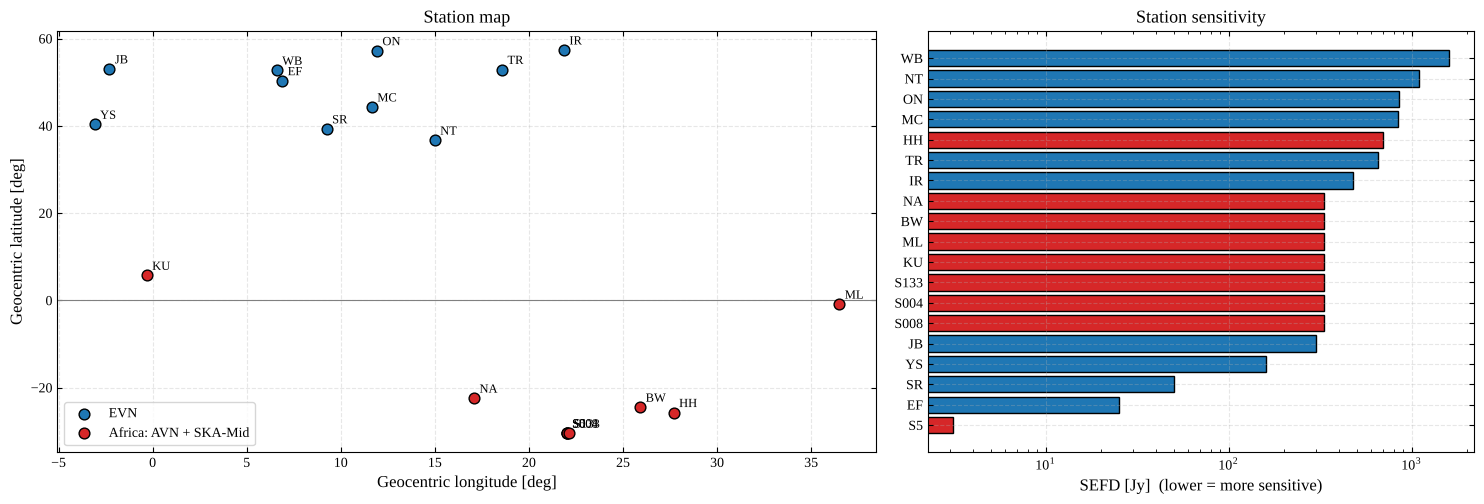

In [4]:
def xyz_to_lonlat(x, y, z):
    return np.degrees(np.arctan2(y, x)), np.degrees(np.arctan2(z, np.hypot(x, y)))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
for group, color, name in [(EVN_STATIONS, 'tab:blue', 'EVN'), (AVN_STATIONS, 'tab:red', 'Africa: AVN + SKA-Mid')]:
    lon, lat = zip(*[xyz_to_lonlat(s[1], s[2], s[3]) for s in group])
    ax.scatter(lon, lat, s=60, color=color, edgecolor='k', zorder=3, label=name)
    for s, lo, la in zip(group, lon, lat):
        ax.annotate(s[0], (lo, la), xytext=(4, 4), textcoords='offset points', fontsize=9)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel("Geocentric longitude [deg]"); ax.set_ylabel("Geocentric latitude [deg]")
ax.set_title("Station map"); ax.legend(loc='lower left')

ax = axes[1]
allst = EVN_STATIONS + AVN_STATIONS
order = np.argsort([s[4] for s in allst])
ax.barh([allst[i][0] for i in order], [allst[i][4] for i in order],
        color=['tab:blue' if allst[i][0] in EVN_SITES else 'tab:red' for i in order], edgecolor='k')
ax.set_xscale('log'); ax.set_xlabel("SEFD [Jy]  (lower = more sensitive)")
ax.set_title("Station sensitivity")
plt.tight_layout()
save_fig(fig, "01_array_map_sefd")

## 2. Sky model: a time-variable precessing jet

### 2.1 The renderer

The ground truth at model-frame `frame_idx` is a **core** (a central Gaussian) plus up to `N_BLOBS` **ejecta pairs** (each one a compact core + a wider halo, mirrored for the counter-jet). Blob *i* is born at `i * SPACING_FRAMES`, moves out at constant speed while its flux decays exponentially (`DECAY_UAS`), and fades linearly when it approaches the edge of the source. The transverse offset follows a helix set by `PRECESSION_PERIOD` and `OPENING_ANGLE`.

> **Why not simply call `Image.add_gauss()`?** The model needs up to ~80 Gaussians *per frame*, and we render 25 frames per observing day. ehtim's `add_gauss` is written as a pure-Python double loop (~80 ms per Gaussian at 256×256), which would add up to ~30 minutes just for the sky model. `gaussian_array()` below uses **exactly the same formula and the same grid convention** but is vectorised with NumPy (~1000× faster). We check the equivalence numerically right after.

In [5]:
RAD = eh.RADPERUAS

def gaussian_array(im, flux, fwhm_rad, x0_rad, y0_rad):
    # Vectorised equivalent of Image.add_gauss for a circular Gaussian (same grid convention, same normalisation).
    sigma = fwhm_rad / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    xl = np.arange(0, -im.xdim, -1) * im.psize + (im.psize * im.xdim) / 2.0 - im.psize / 2.0
    yl = np.arange(0, -im.ydim, -1) * im.psize + (im.psize * im.ydim) / 2.0 - im.psize / 2.0
    X, Y = np.meshgrid(xl - x0_rad, yl - y0_rad)
    g = np.exp(-(X**2 + Y**2) / (2.0 * sigma**2))
    return g * (flux / g.sum())

def get_toy_model_frame(frame_idx, base_image):
    # Ground-truth jet at model-frame `frame_idx` (float). Returns an ehtim Image.
    arr = base_image.imvec.reshape(base_image.ydim, base_image.xdim).copy()
    arr += gaussian_array(base_image, 3000.0 * FLUX_SCALE, 5 * SCALE_FACTOR * RAD, 0.0, 0.0)   # central core

    max_radius = PHYSICAL_SIZE_REF / 1.6
    fade_start = max_radius * 0.95
    for i in range(N_BLOBS):
        birth = i * SPACING_FRAMES
        if birth > 205: continue
        age = frame_idx - birth
        if age < 0: continue
        r = age * VELOCITY_FACTOR
        if r > max_radius: continue

        phase = -2 * np.pi * (birth / PRECESSION_PERIOD) + PHASE_OFFSET
        x_loc, y_loc = r, r * OPENING_ANGLE * np.sin(phase) * 0.8
        x1 = x_loc * np.cos(INCLINATION) - y_loc * np.sin(INCLINATION)
        y1 = x_loc * np.sin(INCLINATION) + y_loc * np.cos(INCLINATION)

        opacity = 1.0 if r <= fade_start else (max_radius - r) / (max_radius - fade_start)
        flux = 7500.0 * FLUX_SCALE * np.exp(-r / DECAY_UAS) * opacity
        if flux > 0.05 * FLUX_SCALE:
            for sgn in (+1, -1):                                   # jet and counter-jet
                arr += gaussian_array(base_image, flux * 0.2, BLOB_HALO_UAS * RAD, sgn * x1 * RAD, sgn * y1 * RAD)
                arr += gaussian_array(base_image, flux,       BLOB_CORE_UAS * RAD, sgn * x1 * RAD, sgn * y1 * RAD)
    out = base_image.copy()
    out.imvec = arr.flatten()
    return out

base_image = eh.image.make_empty(NPIX, OBSERVATION_FOV * RAD, ra=RA_SOURCE, dec=DEC_SOURCE, rf=RF_HZ)

# --- sanity check: vectorised renderer == ehtim's add_gauss ----------------------------------
test_ref = base_image.add_gauss(1e-3, (4000 * RAD, 4000 * RAD, 0, 3000 * RAD, -2000 * RAD))
test_new = gaussian_array(base_image, 1e-3, 4000 * RAD, 3000 * RAD, -2000 * RAD)
print(f"max |add_gauss - gaussian_array| = {np.abs(test_ref.imvec - test_new.flatten()).max():.2e}  "
      f"(peak of the test Gaussian: {test_ref.imvec.max():.2e})")

max |add_gauss - gaussian_array| = 4.24e-22  (peak of the test Gaussian: 3.03e-06)


### 2.2 The campaign at a glance

The `base_frame_idx` of day *d* is `50 + (d-1) * FRAMES_PER_DAY`. Below: the ground truth for 8 days evenly spread over the campaign. Brightness is in mJy/pixel; the axes are relative RA/Dec in mas (RA increases to the left, north is up). The ejecta travel outwards along a helix, and a new pair is launched every ~11 days (`SPACING_FRAMES / FRAMES_PER_DAY`).

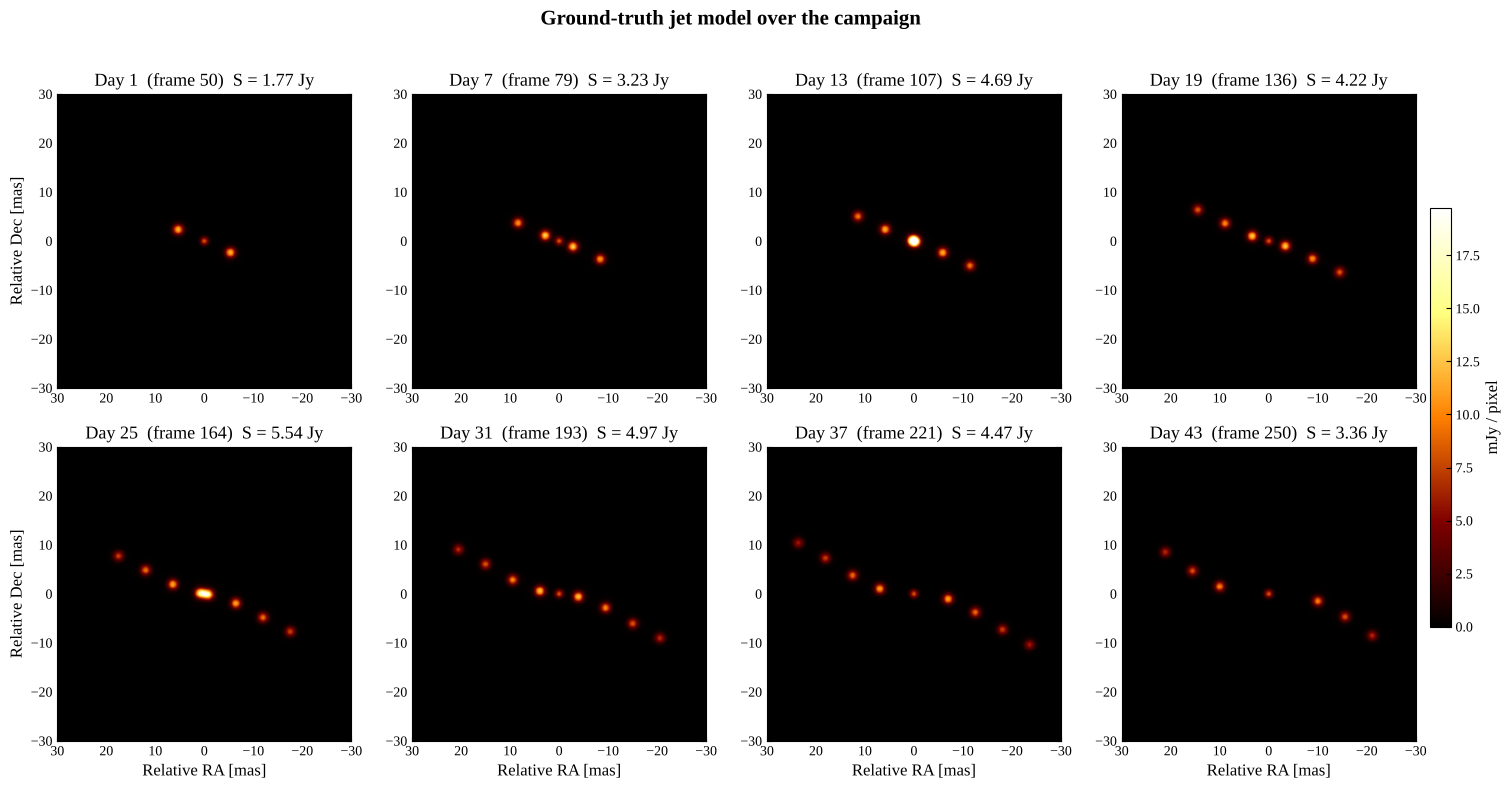

In [6]:
LIMIT_MAS = (OBSERVATION_FOV / 2.0) / 1000.0
EXTENT_MAS = [LIMIT_MAS, -LIMIT_MAS, -LIMIT_MAS, LIMIT_MAS]

def day_to_frame_idx(day):
    return 50 + (day - 1) * FRAMES_PER_DAY

days_show = np.unique(np.linspace(1, N_DAYS, 8).round().astype(int))
frames = {d: get_toy_model_frame(day_to_frame_idx(d), base_image).center() for d in days_show}
vmax_show = max(f.imvec.max() for f in frames.values()) * 1000 * 0.6

fig, axes = plt.subplots(2, 4, figsize=(18, 8.4), facecolor='white')
for ax, d in zip(axes.flat, days_show):
    im = ax.imshow(frames[d].imarr() * 1000, origin='upper', cmap='afmhot', extent=EXTENT_MAS, vmin=0, vmax=vmax_show)
    ax.set_title(f"Day {d}  (frame {day_to_frame_idx(d):.0f})  S = {frames[d].total_flux():.2f} Jy")
    ax.set_xlim(LIMIT_MAS, -LIMIT_MAS); ax.set_ylim(-LIMIT_MAS, LIMIT_MAS)
    ax.grid(False)
for ax in axes[1]: ax.set_xlabel("Relative RA [mas]")
for ax in axes[:, 0]: ax.set_ylabel("Relative Dec [mas]")
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01).set_label("mJy / pixel")
fig.suptitle("Ground-truth jet model over the campaign", fontsize=15, fontweight='bold')
save_fig(fig, "02_ground_truth_montage")

## 3. Observing engine: from a movie to time-variable visibilities

A real VLBI track lasts hours, and the source *changes* during it. We take this into account with an `eh.movie.Movie`: for each observing day we render ~25 frames spanning the track (plus a 0.1 h padding) and let `Movie.observe_same()` sample the right frame at each visibility time. This is a faithful way of simulating the **visibilities of a source that evolves during the observation**, something a static `Image.observe()` cannot do.

The procedure for a given day, array and scenario:

1. **Template observation**: observe the *central frame* (`im_truth`) with the array. This fixes the scan schedule, the elevation cuts and the baseline sampling (`tint=12 s`, `tadv=240 s`). We keep only time stamps with at least 3 baselines, so that closure quantities exist.
2. **Movie observation**: re-observe the same schedule with the full movie, adding the errors of the chosen scenario.

**Observing window.** `get_optimal_observation_window()` centres a 6-hour track on the source transit at the reference longitude, using the GMST at `MJD_START`.

> **Modelling choice (shared with the full-campaign script):** the window is computed once from `MJD_START` and reused every day, so the **uv-coverage is identical on every day**. What changes from day to day is the *source* (it evolves) and the *random error realisations*. This is a deliberate simplification: it isolates the effect of source variability. To get the real day-to-day sidereal shift (≈ 4 min/day) you would pass `MJD_START + day` instead.

In [7]:
def get_optimal_observation_window(mjd, ra_hr=RA_SOURCE, duration=WINDOW_HOURS, lon_hr=10.0 / 15.0):
    # UTC start/stop [h] of a `duration`-hour track centred on the source transit.
    T = (mjd - 51544.5) / 36525.0
    gmst_0h = (6.697374558 + 2400.051336 * T + 0.000025862 * T**2) % 24.0
    transit_utc = ((ra_hr - gmst_0h - lon_hr) % 24.0) * 0.99726958
    start_hr, end_hr = transit_utc - duration / 2.0, transit_utc + duration / 2.0
    if end_hr >= 23.9:
        shift = end_hr - 23.9; start_hr -= shift; end_hr -= shift
    elif start_hr <= 0.1:
        shift = 0.1 - start_hr; start_hr += shift; end_hr += shift
    return start_hr, end_hr

def build_movie(base_frame_idx, base_img, start_hr, end_hr, factor=TIME_FACTOR, fps_sim=FPS_SIM, pad=0.1):
    # Movie of the evolving source over the track. Returns (movie, im_truth_at_central_frame).
    t0, t1 = start_hr - pad, end_hr + pad
    duration = t1 - t0
    n_frames = int(duration * fps_sim) + 1
    times = list(np.linspace(t0, t1, n_frames))
    arrays, truth = [], None
    for i in range(n_frames):
        frac = i / (n_frames - 1) - 0.5
        frame = base_frame_idx + frac * (duration / 24.0) * FRAMES_PER_DAY * factor
        im = get_toy_model_frame(frame, base_img).center()
        im.mjd = MJD_START
        arrays.append(im.imarr())
        if i == n_frames // 2:
            truth = im.copy()
    movie = eh.movie.Movie(arrays, times=times, psize=base_img.psize, ra=base_img.ra,
                           dec=base_img.dec, rf=base_img.rf, mjd=MJD_START)
    return movie, truth

def make_template(truth, array, start_hr, end_hr, err):
    # Scan schedule + a first realisation of the errors, from the central frame.
    with quiet():
        tmpl = truth.observe(array, tint=TINT_S, tadv=TADV_S, tstart=start_hr, tstop=end_hr, bw=BW_HZ,
                             ttype=TTYPE, elevmin=ELEVMIN,
                             ampcal=err['ampcal'], phasecal=err['phasecal'],
                             gain_offset=err['gain_offset'], gainp=err['gainp'], verbose=False)
    if len(tmpl.data) == 0:
        return None
    times_u, counts = np.unique(tmpl.data['time'], return_counts=True)
    valid = times_u[counts >= 3]                          # at least 3 baselines (closures need triangles)
    if len(valid) == 0:
        return None
    tmpl.data = tmpl.data[np.isin(tmpl.data['time'], valid)]
    return tmpl

def observe_with_movie(movie, tmpl, err):
    # Observe the evolving source on the template's schedule, with the scenario's errors.
    try:
        with quiet():
            obs = movie.observe_same(tmpl, ttype=TTYPE, ampcal=err['ampcal'], phasecal=err['phasecal'],
                                     gain_offset=err['gain_offset'], gainp=err['gainp'], verbose=False)
        return obs
    except Exception as e:
        print(f"   [!] movie.observe_same failed: {e}")
        return None

START_HR, END_HR = get_optimal_observation_window(MJD_START)
print(f"Observing window (UTC): {START_HR:.2f} h -> {END_HR:.2f} h  ({END_HR - START_HR:.1f} h track)")

Observing window (UTC): 17.90 h -> 23.90 h  (6.0 h track)


## 4. Campaign simulation: every day, both arrays, both scenarios

For each of the `N_DAYS` days we build **one** movie (shared by the four datasets, which saves a lot of time) and observe it with {EVN (no SKA), EVN+AVN+SKA-Mid} × {A, B}. Everything is kept in memory in the dictionary `OBS[(array, scenario)][day]`.

For `IMAGING_DAY` we additionally compute the **noise-free observation of the same schedule** (`IDEAL[(array, scenario)]`, via `Movie.observe_same_nonoise`). It is the *exact* error-free reference needed later to measure the corruption injected by each scenario, visibility by visibility.

Depending on `SAVE_UVFITS`, the observations are written as `.uvfits` (and `.txt`) files, directly usable in AIPS, CASA or Difmap.

In [8]:
OBS   = {(a, s): {} for a in ARRAYS for s in SCENARIOS}      # OBS[(array, scenario)][day] -> Obsdata
IDEAL = {}                                                   # noise-free obs, imaging day only
TRUTH_ARR, TRUTH_FLUX, TRUTH_PEAK = {}, {}, {}               # per-day ground truth (image array, total flux, peak)
TRUTH_IM = None                                              # ehtim Image of the imaging day

np.random.seed(SEED)
t_campaign = time.time()
day, offset = 0, 0
print(f"Simulating {N_DAYS} days x {len(ARRAYS)} arrays x {len(SCENARIOS)} scenarios "
      f"= {N_DAYS * len(ARRAYS) * len(SCENARIOS)} observations\n")

while day < N_DAYS:
    if offset >= MAX_ATTEMPTS:
        print("[!] Attempt limit reached."); break
    movie, truth = build_movie(50 + offset * FRAMES_PER_DAY, base_image, START_HR, END_HR)

    done, ok = {}, True
    for a_key, array in ARRAYS.items():
        for s_key, err in SCENARIOS.items():
            tmpl = make_template(truth, array, START_HR, END_HR, err)
            obs = observe_with_movie(movie, tmpl, err) if tmpl is not None else None
            if obs is None:
                ok = False; break
            obs.mjd = MJD_START + offset
            done[(a_key, s_key)] = (obs, tmpl)
        if not ok: break
    if not ok:
        print(f"   day attempt {offset}: no usable data, skipping"); offset += 1; continue

    day += 1
    for key, (obs, tmpl) in done.items():
        OBS[key][day] = obs
    TRUTH_ARR[day]  = truth.imarr().astype(np.float32)
    TRUTH_FLUX[day] = truth.total_flux()
    TRUTH_PEAK[day] = float(truth.imvec.max())

    if day == IMAGING_DAY:
        TRUTH_IM = truth.copy()
        for key, (obs, tmpl) in done.items():
            with quiet():
                IDEAL[key] = movie.observe_same_nonoise(tmpl, ttype=TTYPE, verbose=False)

    if SAVE_UVFITS == 'all' or (SAVE_UVFITS == 'imaging_day' and day == IMAGING_DAY):
        for (a_key, s_key), (obs, _) in done.items():
            tag = f"{ARRAY_TAG[a_key]}_{s_key}"
            os.makedirs(f"{UV_DIR}/{tag}", exist_ok=True)
            with quiet():
                obs.save_uvfits(f"{UV_DIR}/{tag}/obs_day_{day:02d}.uvfits")
                obs.save_txt(f"{UV_DIR}/{tag}/obs_day_{day:02d}.txt")

    n_e, n_c = len(done[("EVN (no SKA)", "A")][0].data), len(done[("EVN+AVN+SKA-Mid", "A")][0].data)
    if day % 5 == 0 or day in (1, N_DAYS) or day == IMAGING_DAY:
        print(f"day {day:02d}/{N_DAYS} | S_truth = {TRUTH_FLUX[day]:.3f} Jy | N_vis: EVN (no SKA) = {n_e}, EVN+AVN+SKA-Mid = {n_c} "
              f"| elapsed {(time.time() - t_campaign) / 60:.1f} min")
    del movie
    offset += 1

print(f"\nCampaign simulated in {(time.time() - t_campaign) / 60:.1f} min.")
assert TRUTH_IM is not None, "IMAGING_DAY was not simulated"

Simulating 43 days x 2 arrays x 2 scenarios = 172 observations



day 01/43 | S_truth = 1.774 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 0.3 min


day 05/43 | S_truth = 3.347 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 1.7 min


day 10/43 | S_truth = 3.070 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 3.4 min


day 15/43 | S_truth = 4.530 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 5.1 min


day 20/43 | S_truth = 4.146 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 6.8 min


... (2 outputs left out)

day 30/43 | S_truth = 5.063 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 10.6 min


day 35/43 | S_truth = 4.630 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 12.4 min


day 40/43 | S_truth = 3.536 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 14.1 min


day 43/43 | S_truth = 3.356 Jy | N_vis: EVN (no SKA) = 3999, EVN+AVN+SKA-Mid = 15089 | elapsed 15.1 min

Campaign simulated in 15.1 min.


## 5. uv-plane and data statistics (imaging day)

Everything in this section uses the observations of `IMAGING_DAY` and needs **no imaging at all**: it is the kind of analysis you would put in an observing proposal to justify an array choice.

### 5.1 uv-coverage: EVN (no SKA) vs. EVN+AVN+SKA-Mid

Each visibility measures one Fourier component of the sky at the point $(u,v)$, in units of wavelengths (here M$\lambda$). Because the sky brightness is real, each point also implies its conjugate $(-u,-v)$, which we draw too.

- **Left / centre:** the coverage of EVN (no SKA) and EVN+AVN+SKA-Mid coloured by **UTC time**: you can see the Earth-rotation arcs being traced during the track.
- **Right:** EVN+AVN+SKA-Mid coloured by **baseline class**. The *EVN–Africa* baselines (red; Africa = AVN + SKA-Mid stations) are the long Europe–Africa baselines that stretch the coverage in the north–south direction, and the *Africa–Africa* ones (green, including the short SKA-Mid baselines) fill the short spacings in the centre.

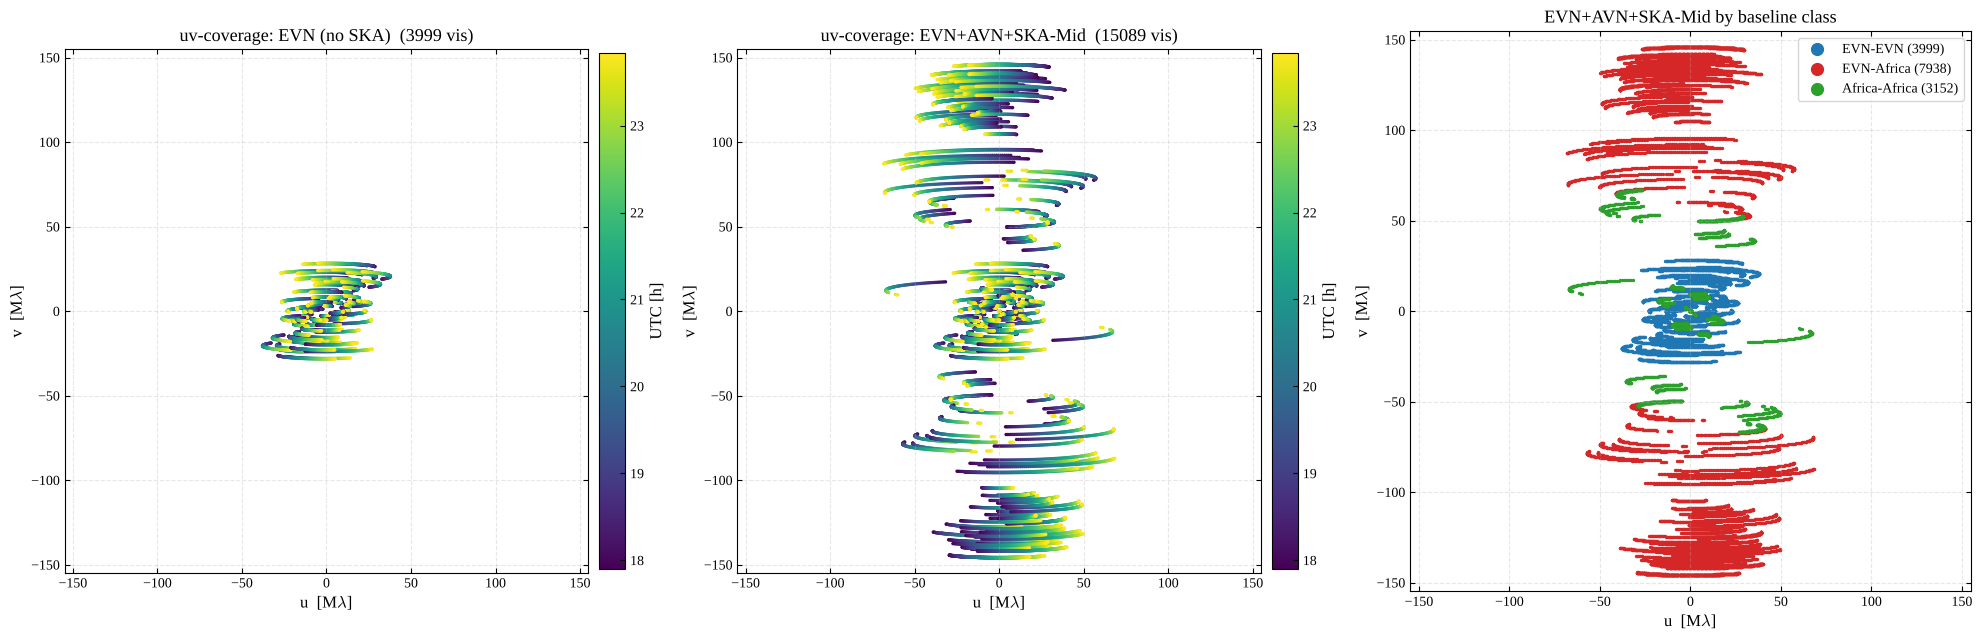

In [9]:
CLASS_COLOR = {"EVN-EVN": "tab:blue", "EVN-Africa": "tab:red", "Africa-Africa": "tab:green"}

def baseline_class(obs):
    t1, t2 = obs.data['t1'].astype(str), obs.data['t2'].astype(str)
    a1, a2 = np.isin(t1, AVN_SITES), np.isin(t2, AVN_SITES)
    return np.where(a1 & a2, "Africa-Africa", np.where(a1 | a2, "EVN-Africa", "EVN-EVN"))

def uv_dist(obs):                     # |(u,v)| in M-lambda
    return np.hypot(obs.data['u'], obs.data['v']) / 1e6

obs_evn_A  = OBS[("EVN (no SKA)", "A")][IMAGING_DAY]
obs_comb_A = OBS[("EVN+AVN+SKA-Mid", "A")][IMAGING_DAY]
lim = 1.05 * uv_dist(obs_comb_A).max()

fig, axes = plt.subplots(1, 3, figsize=(20, 6.3))
for ax, obs, title in [(axes[0], obs_evn_A, "EVN (no SKA)"), (axes[1], obs_comb_A, "EVN+AVN+SKA-Mid")]:
    u, v, t = obs.data['u'] / 1e6, obs.data['v'] / 1e6, obs.data['time']
    sc = ax.scatter(np.r_[u, -u], np.r_[v, -v], c=np.r_[t, t], s=2, cmap='viridis')
    ax.set_title(f"uv-coverage: {title}  ({len(obs.data)} vis)")
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02).set_label("UTC [h]")
ax = axes[2]
cls = baseline_class(obs_comb_A)
u, v = obs_comb_A.data['u'] / 1e6, obs_comb_A.data['v'] / 1e6
for c, col in CLASS_COLOR.items():
    m = cls == c
    ax.scatter(np.r_[u[m], -u[m]], np.r_[v[m], -v[m]], s=2, color=col, label=f"{c} ({m.sum()})")
ax.set_title("EVN+AVN+SKA-Mid by baseline class"); ax.legend(markerscale=6, loc='upper right')
for ax in axes:
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xlabel(r"u  [M$\lambda$]"); ax.set_ylabel(r"v  [M$\lambda$]")
plt.tight_layout()
save_fig(fig, "03_uv_coverage")

### 5.2 Who observes when, and how long are the baselines?

- **Left — station availability:** each tick is a time at which that station contributes at least one visibility. Stations whose ticks stop early or start late are limited by the elevation cut. This is what makes the *effective* array different from the nominal one.
- **Centre — baseline-length distribution** (in M$\lambda$, stacked by class for EVN+AVN+SKA-Mid; the black line is EVN alone (no SKA)).
- **Right — cumulative distribution:** the fraction of visibilities that sample structures *larger* than a given angular scale $\theta \sim 1/|uv|$ (top axis, in mas). Short baselines constrain the extended emission and long baselines the compact structure.

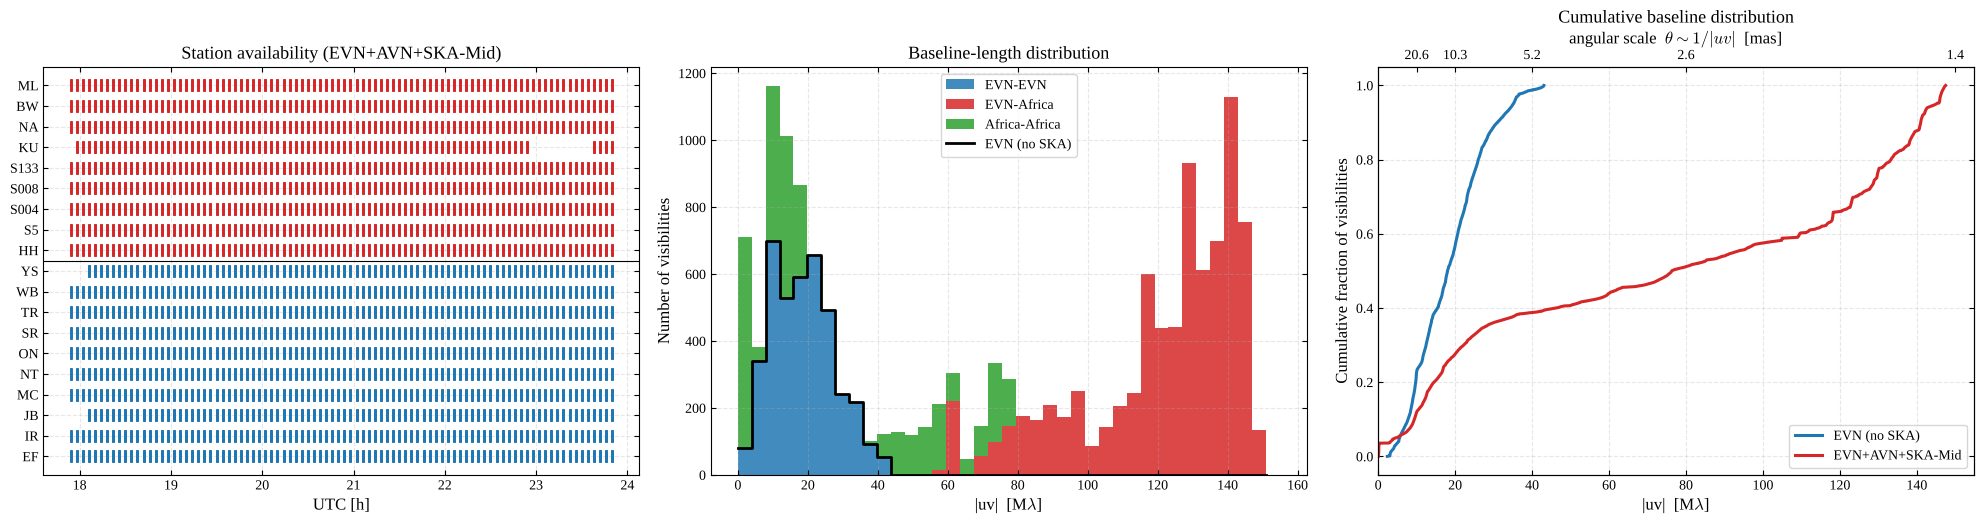

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.4))

# (a) station availability
ax = axes[0]
sites = EVN_SITES + AVN_SITES
t1, t2 = obs_comb_A.data['t1'].astype(str), obs_comb_A.data['t2'].astype(str)
tt = obs_comb_A.data['time']
for i, s in enumerate(sites):
    m = (t1 == s) | (t2 == s)
    ax.plot(tt[m], np.full(m.sum(), i), '|', color='tab:blue' if s in EVN_SITES else 'tab:red', markersize=9)
ax.set_yticks(range(len(sites))); ax.set_yticklabels(sites)
ax.set_xlabel("UTC [h]"); ax.set_title("Station availability (EVN+AVN+SKA-Mid)")
ax.axhline(len(EVN_SITES) - 0.5, color='k', lw=0.8)

# (b) baseline-length histogram
ax = axes[1]
bins = np.linspace(0, lim, 40)
d_c, cls = uv_dist(obs_comb_A), baseline_class(obs_comb_A)
ax.hist([d_c[cls == c] for c in CLASS_COLOR], bins=bins, stacked=True,
        color=list(CLASS_COLOR.values()), label=list(CLASS_COLOR), alpha=0.85)
h, _ = np.histogram(uv_dist(obs_evn_A), bins=bins)
ax.step(bins[:-1], h, where='post', color='k', lw=2, label='EVN (no SKA)')
ax.set_xlabel(r"|uv|  [M$\lambda$]"); ax.set_ylabel("Number of visibilities"); ax.legend()
ax.set_title("Baseline-length distribution")

# (c) cumulative distribution + angular scale axis
ax = axes[2]
for name, obs in [("EVN (no SKA)", obs_evn_A), ("EVN+AVN+SKA-Mid", obs_comb_A)]:
    d = np.sort(uv_dist(obs)); ax.plot(d, np.arange(1, len(d) + 1) / len(d), lw=2.2, color=AR_COLOR[name], label=name)
ax.set_xlabel(r"|uv|  [M$\lambda$]"); ax.set_ylabel("Cumulative fraction of visibilities"); ax.legend(loc='lower right')
ax.set_xlim(0, lim)
ax_top = ax.twiny(); ax_top.set_xlim(ax.get_xlim()); ax_top.grid(False)
tick_uv = np.array([10, 20, 40, 80, 150]); tick_uv = tick_uv[tick_uv <= lim]
ax_top.set_xticks(tick_uv)
ax_top.set_xticklabels([f"{1.0 / (t * 1e6) / RAD / 1e3:.1f}" for t in tick_uv])    # theta = 1/|uv|  [mas]
ax_top.set_xlabel(r"angular scale  $\theta \sim 1/|uv|$  [mas]")
ax.set_title("Cumulative baseline distribution")
plt.tight_layout()
save_fig(fig, "04_station_availability_baselines")

### 5.3 Quantitative summary of the arrays

For each array: how many baselines were really used, the range of projected lengths, and the resulting resolutions. Two angular scales matter:

- $\theta_{\rm res} \sim 1/B_{\max}$: the finest detail the array can probe, set by the **longest** projected baseline.
- $\theta_{\rm LAS} \sim 1/B_{\min}$: the **largest angular scale** that is still sampled. Structure larger than this is *resolved out* (no flux is recovered from it).

The **fitted clean beam** (`obs.fit_beam()`) is the practical resolution of the final images: it also depends on how the uv-plane is *filled*, not only on $B_{\max}$.

In [11]:
def baseline_pairs(obs):
    return set(zip(obs.data['t1'].astype(str), obs.data['t2'].astype(str)))

rows = []
for name, obs, arr in [("EVN (no SKA)", obs_evn_A, array_evn), ("EVN+AVN+SKA-Mid", obs_comb_A, array_comb)]:
    d = uv_dist(obs)
    bmaj, bmin, pa = obs.fit_beam()
    n_st = len(arr.tarr)
    rows.append({
        "Array": name, "Stations": n_st, "Nominal baselines": n_st * (n_st - 1) // 2,
        "Active baselines": len(baseline_pairs(obs)), "N visibilities": len(obs.data),
        "Bmin [Mlambda]": d.min(), "Bmedian [Mlambda]": np.median(d), "Bmax [Mlambda]": d.max(),
        "1/Bmax [uas]": 1.0 / (d.max() * 1e6) / RAD, "1/Bmin [mas]": 1.0 / (d.min() * 1e6) / RAD / 1e3,
        "Beam major [mas]": bmaj / RAD / 1e3, "Beam minor [mas]": bmin / RAD / 1e3, "Beam PA [deg]": np.degrees(pa),
    })
df_arrays = pd.DataFrame(rows).set_index("Array").T
display(df_arrays.round(2))

# --- per baseline class: how sensitive is each kind of baseline? ---------------------------------
cls = baseline_class(obs_comb_A)
rows = []
for c in CLASS_COLOR:
    m = cls == c
    sig = obs_comb_A.data['sigma'][m]
    snr = np.abs(obs_comb_A.data['vis'][m]) / sig
    rows.append({"Class": c, "N vis": int(m.sum()), "Median |uv| [Mlambda]": np.median(uv_dist(obs_comb_A)[m]),
                 "Median thermal sigma [mJy]": np.median(sig) * 1e3, "Median SNR": np.median(snr)})
print("\nEVN+AVN+SKA-Mid, scenario A: statistics per baseline class")
display(pd.DataFrame(rows).set_index("Class").round(2))

Array,EVN (no SKA),EVN+AVN+SKA-Mid
Stations,10.00,19.00
Nominal baselines,45.00,171.00
Active baselines,45.00,171.00
N visibilities,3999.00,15089.00
Bmin [Mlambda],2.40,0.01
Bmedian [Mlambda],18.01,76.31
Bmax [Mlambda],43.06,147.47
1/Bmax [uas],4789.63,1398.70
1/Bmin [mas],85.97,19446.63
Beam major [mas],7.56,3.85



EVN+AVN+SKA-Mid, scenario A: statistics per baseline class


,N vis,Median |uv| [Mlambda],Median thermal sigma [mJy],Median SNR
Class,,,,
EVN-EVN,3999,18.01,5.50,91.21
EVN-Africa,7938,128.72,5.77,8.13
Africa-Africa,3152,15.46,4.78,154.30


### 5.4 Dirty beams

The **dirty beam** is the array's response to a point source (normalised here to 1 at its centre; `ehtim`'s `dirtybeam()` divides it by its sum over the image, which is close to zero without zero-spacing baselines and can even be negative, as it is for the EVN here): the Fourier transform of the uv sampling (uniform weighting here). Imaging is, loosely speaking, the process of *deconvolving* this pattern from the data. The black contour is the half-maximum level of the **fitted elliptical clean beam**. Compare the shape of the side-lobes: a better-filled uv-plane gives a cleaner beam and a rounder, smaller main lobe.

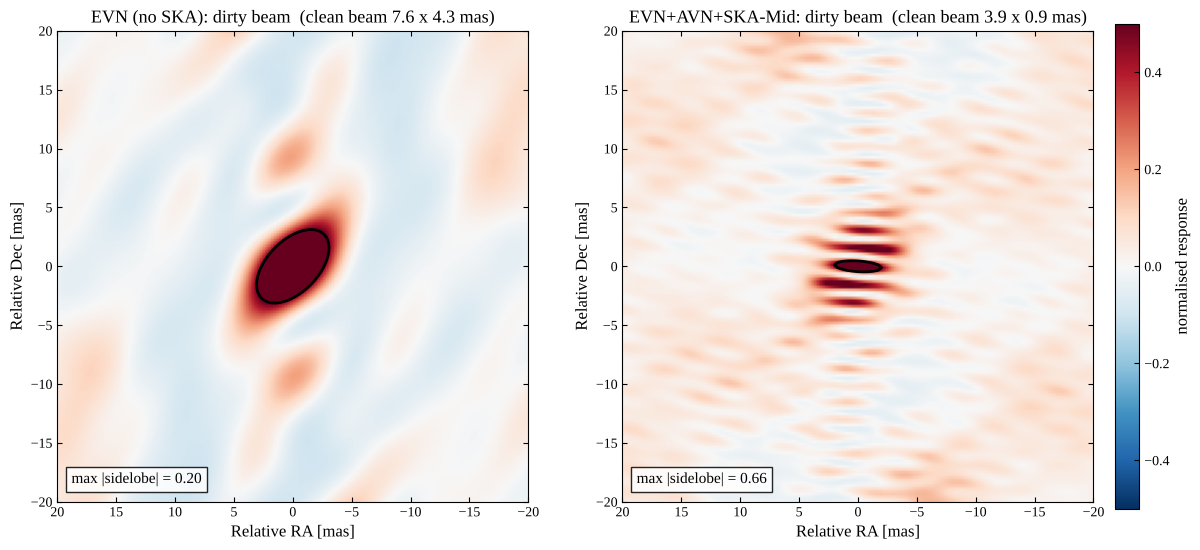

In [12]:
fov_rad = OBSERVATION_FOV * RAD
empty_grid = eh.image.make_empty(NPIX, fov_rad, ra=RA_SOURCE, dec=DEC_SOURCE, rf=RF_HZ)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.3))
ZOOM = 20.0     # mas
for ax, (name, obs) in zip(axes, [("EVN (no SKA)", obs_evn_A), ("EVN+AVN+SKA-Mid", obs_comb_A)]):
    with quiet():
        dbeam = obs.dirtybeam(NPIX, fov_rad)
    bp = obs.fit_beam()
    clean_beam = empty_grid.add_gauss(1.0, (bp[0], bp[1], bp[2], 0, 0))
    arr = dbeam.imarr(); arr = arr / arr[NPIX // 2, NPIX // 2]      # peak = 1 at the phase centre
    im = ax.imshow(arr, origin='upper', cmap='RdBu_r', vmin=-0.5, vmax=0.5, extent=EXTENT_MAS)
    cb = clean_beam.imarr(); cb = cb / cb.max()
    ax.contour(np.linspace(LIMIT_MAS, -LIMIT_MAS, NPIX), np.linspace(LIMIT_MAS, -LIMIT_MAS, NPIX), cb,   # row 0 = north
               levels=[0.5], colors='k', linewidths=2)
    ax.set_xlim(ZOOM, -ZOOM); ax.set_ylim(-ZOOM, ZOOM); ax.grid(False)
    ax.set_title(f"{name}: dirty beam  (clean beam {bp[0]/RAD/1e3:.1f} x {bp[1]/RAD/1e3:.1f} mas)")
    ax.set_xlabel("Relative RA [mas]"); ax.set_ylabel("Relative Dec [mas]")
    # peak sidelobe level (outside the clean beam FWHM region)
    mask = cb < 0.05
    ax.text(0.03, 0.04, f"max |sidelobe| = {np.abs(arr[mask]).max():.2f}", transform=ax.transAxes,
            bbox=dict(facecolor='white', alpha=0.85), fontsize=11)
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02).set_label("normalised response")
save_fig(fig, "05_dirty_beams")

### 5.5 Visibilities: ideal vs. Scenario A vs. Scenario B

The classic diagnostic: visibility **amplitude** and **phase** vs. $|uv|$ (here for `IMAGING_DAY`), for both arrays. Because we kept the noise-free reference `IDEAL`, we can also look at the *corruption itself* (observed / ideal), which is something you can never do with real data.

Columns: **(1)** amplitude vs $|uv|$ (log scale; black = noise-free), **(2)** amplitude ratio observed / ideal, **(3)** raw visibility phase, **(4)** phase residual observed − ideal.

What to expect:
- **Scenario A** (thermal noise only) hugs the ideal curve; its scatter grows on the long, faint baselines where SNR is lowest.
- **Scenario B** shows amplitude errors of order 10–30 % (station gains, scaling *whole sets of baselines* coherently) and phases that are scrambled over the full $[-180°, 180°]$ range, because the uncorrected atmospheric phase is far larger than the source's own phase signal.

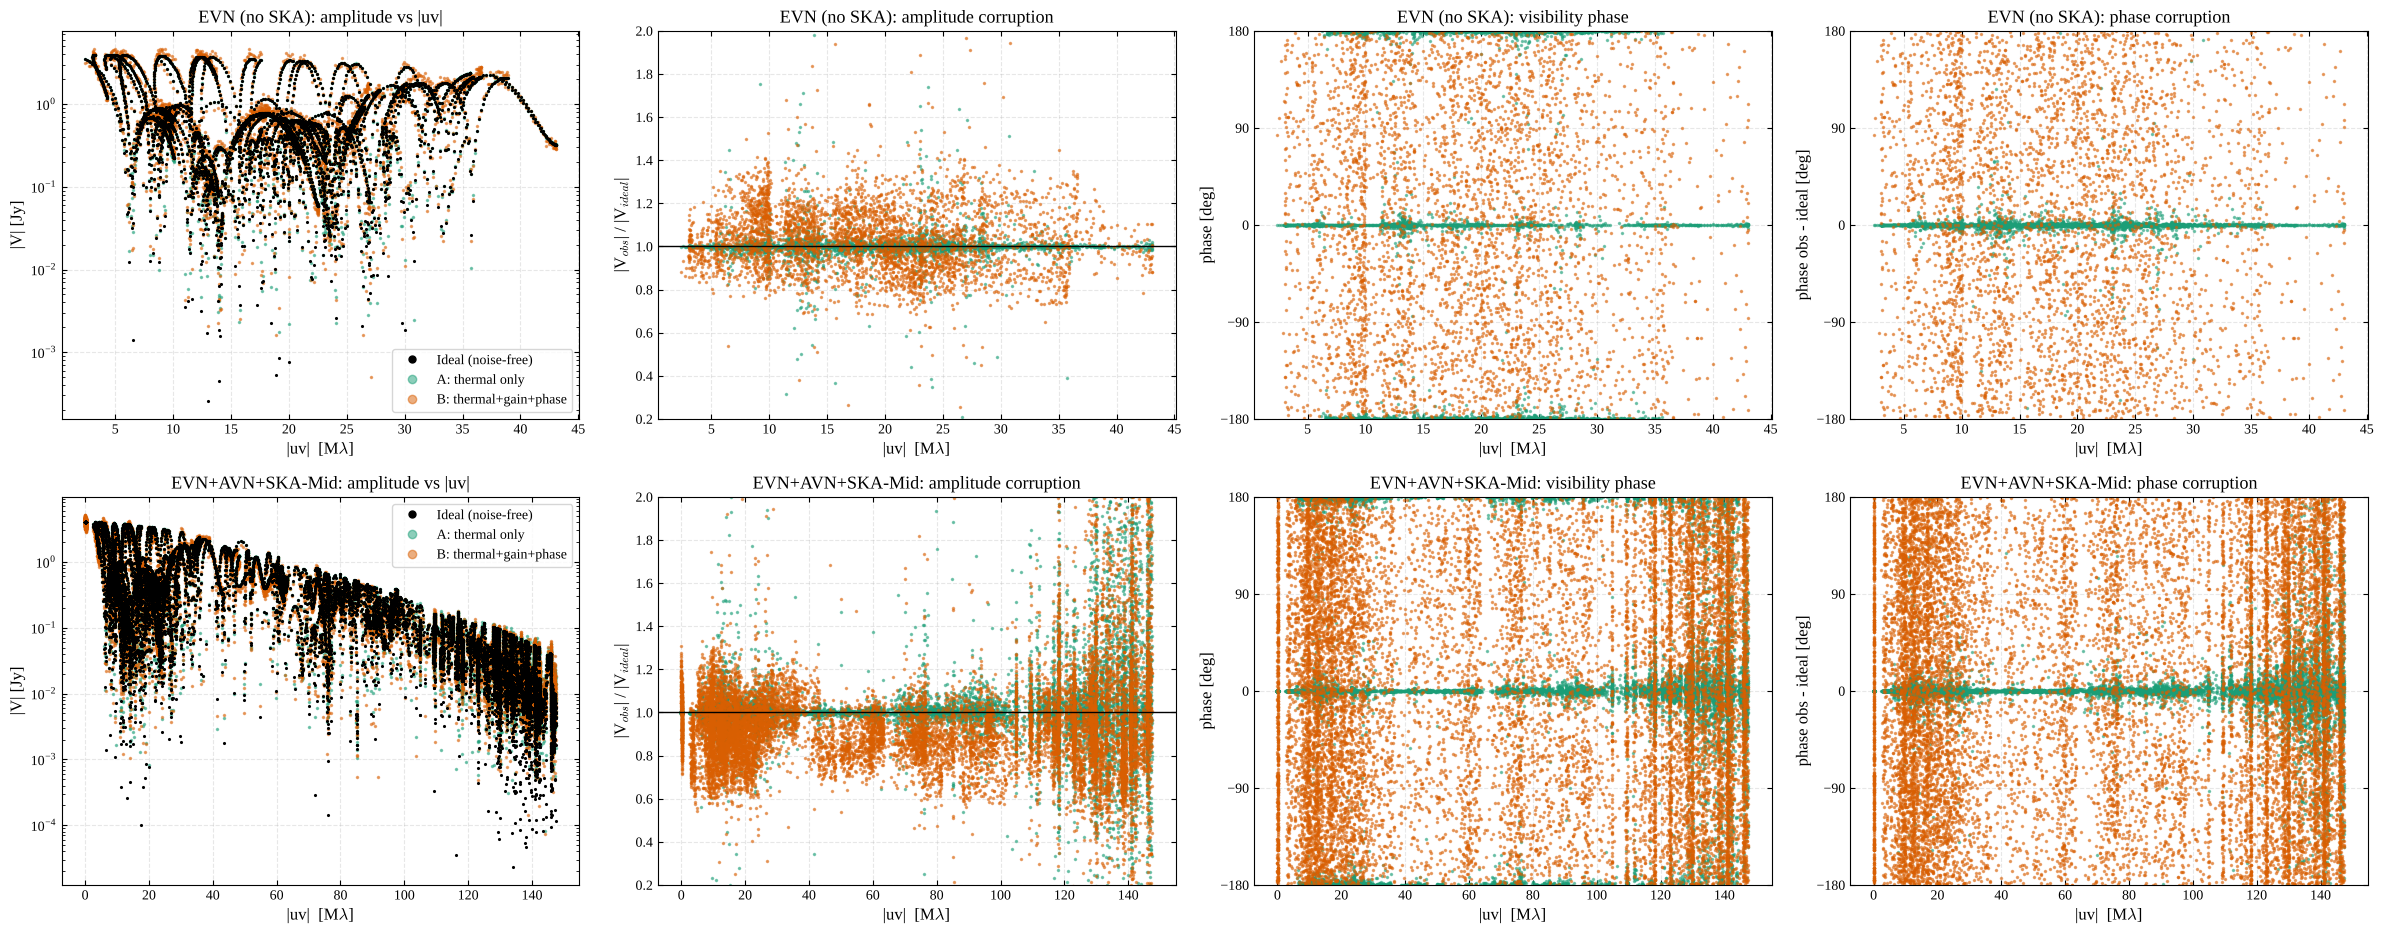

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(24, 9.5))
for r, a_key in enumerate(ARRAYS):
    ideal = IDEAL[(a_key, "A")]
    d_id = uv_dist(ideal)
    ax1, ax2, ax3, ax4 = axes[r]
    ax1.plot(d_id, np.abs(ideal.data['vis']), '.', color='k', ms=2.5, label='Ideal (noise-free)', zorder=5)
    for s_key in SCENARIOS:
        obs = OBS[(a_key, s_key)][IMAGING_DAY]
        ide = IDEAL[(a_key, s_key)]
        d = uv_dist(obs)
        amp_o, amp_i = np.abs(obs.data['vis']), np.abs(ide.data['vis'])
        col = SC_COLOR[s_key]
        ax1.plot(d, amp_o, '.', ms=3, alpha=0.5, color=col, label=SCENARIOS[s_key]['label'])
        ax2.plot(d, amp_o / amp_i, '.', ms=3, alpha=0.5, color=col)
        ax3.plot(d, np.angle(obs.data['vis'], deg=True), '.', ms=3, alpha=0.5, color=col)
        ax4.plot(d, np.angle(obs.data['vis'] * np.conj(ide.data['vis']), deg=True), '.', ms=3, alpha=0.5, color=col)
    ax1.set_yscale('log'); ax1.set_ylabel("|V| [Jy]"); ax1.legend(markerscale=4)
    ax1.set_title(f"{a_key}: amplitude vs |uv|")
    ax2.axhline(1, color='k', lw=1); ax2.set_ylim(0.2, 2.0); ax2.set_ylabel(r"|V$_{obs}$| / |V$_{ideal}$|")
    ax2.set_title(f"{a_key}: amplitude corruption")
    ax3.set_ylim(-180, 180); ax3.set_yticks([-180, -90, 0, 90, 180]); ax3.set_ylabel("phase [deg]")
    ax3.set_title(f"{a_key}: visibility phase")
    ax4.set_ylim(-180, 180); ax4.set_yticks([-180, -90, 0, 90, 180]); ax4.set_ylabel("phase obs - ideal [deg]")
    ax4.set_title(f"{a_key}: phase corruption")
    for ax in (ax1, ax2, ax3, ax4): ax.set_xlabel(r"|uv|  [M$\lambda$]")
plt.tight_layout()
save_fig(fig, "06_visibility_amp_phase")

### 5.6 Corruption statistics and the invariance of closure quantities

Now we quantify the corruption and verify the key property of closure quantities with the *data*, not with images:

- **Amplitude** corruption: the distribution of $\ln(|V_{obs}|/|V_{ideal}|)$. In Scenario A it is a narrow Gaussian set by thermal noise; in Scenario B it is broadened by the station gains.
- **Phase** corruption: the distribution of $\arg(V_{obs}V^*_{ideal})$. Scenario B is essentially uniform.
- **Closure phase** corruption: $\psi_{obs} - \psi_{ideal}$ over all (minimal-set) triangles. Because the station phases cancel in the closure sum, **the Scenario A and B distributions should coincide**: only thermal noise survives. This is why closure quantities are the backbone of VLBI imaging when calibration is poor.

> **Why a robust standard deviation?** Low-SNR triangles have a very large, non-Gaussian thermal error, and a handful of them wrap around $\pm180°$. The plain standard deviation is dominated by those outliers (and, since A and B use *independent* noise realisations, it can differ a lot between them). We therefore quote $1.4826 \times$ MAD, which measures the width of the bulk of the distribution. Small residual differences between A and B are expected: they are different random realisations of the thermal noise.

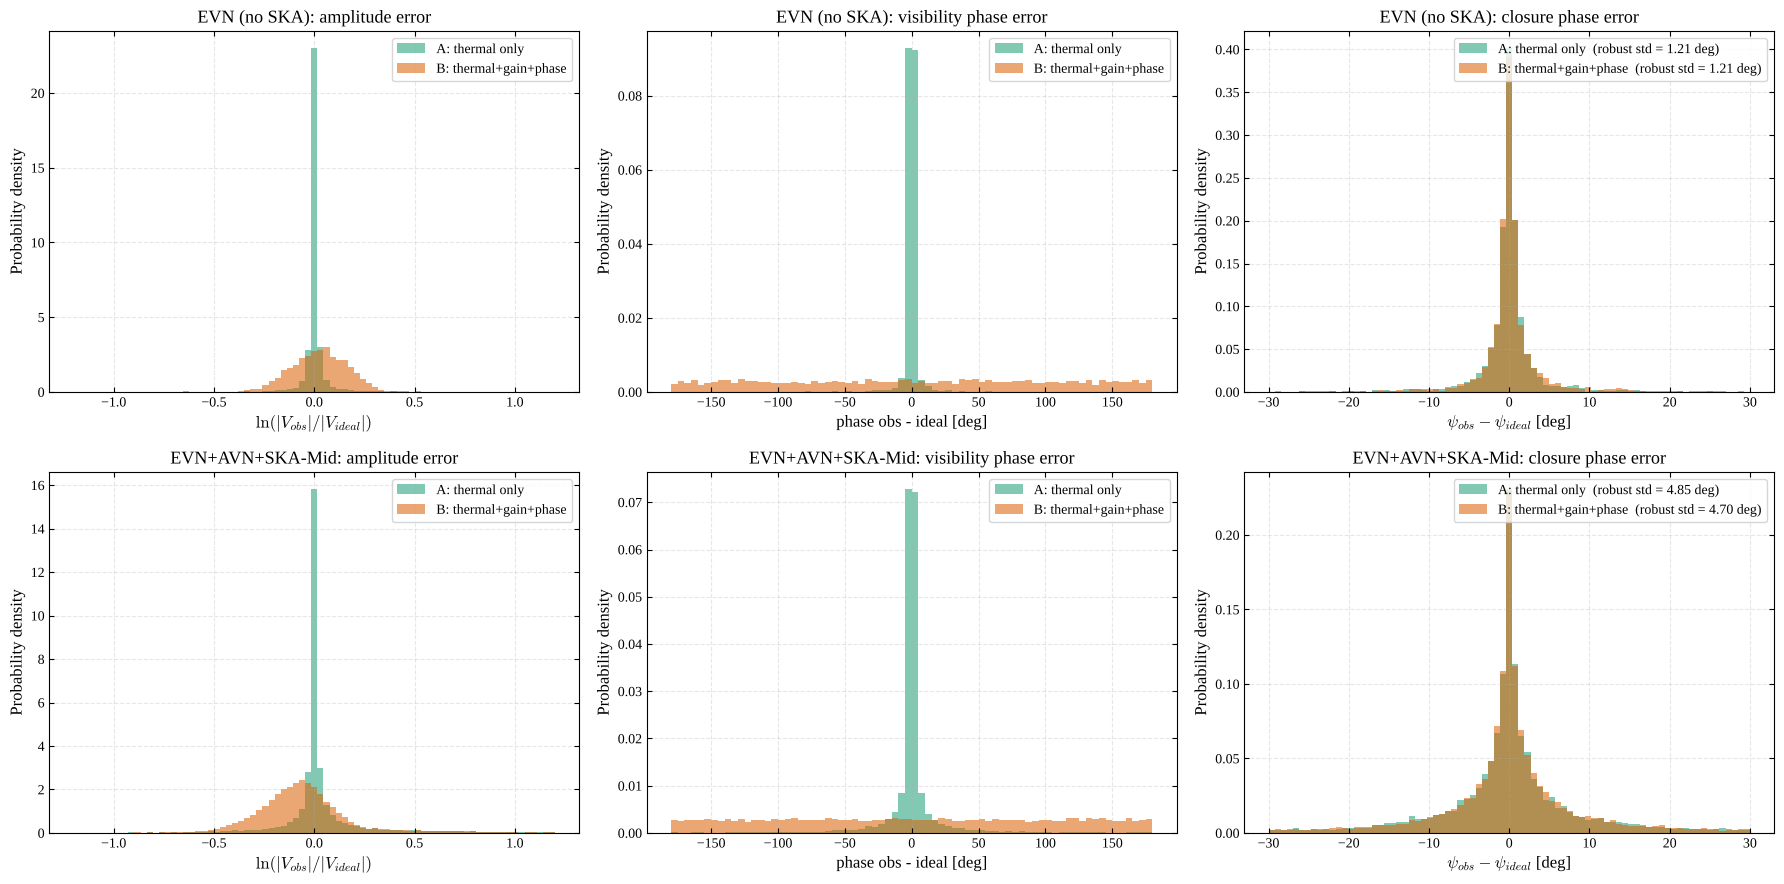

N vis  Median SNR  \
Array           Scenario                      
EVN (no SKA)    A          3999      91.351   
                B          3999      91.173   
EVN+AVN+SKA-Mid A         15089      29.963   
                B         15089      29.901   

                          Amp error: robust std of ln ratio  \
Array           Scenario                                      
EVN (no SKA)    A                                     0.009   
                B                                     0.146   
EVN+AVN+SKA-Mid A                                     0.028   
                B                                     0.182   

                          Amp error: median ratio  \
Array           Scenario                            
EVN (no SKA)    A                           1.000   
                B                           1.030   
EVN+AVN+SKA-Mid A                           1.001   
                B                           0.934   

                          Vis phase error: circ. std [deg]  \
Array           Scenario                                     
EVN (no SKA)    A                                    8.647   
                B                                  168.819   
EVN+AVN+SKA-Mid A                                   21.929   
                B                                  188.949   

                          Closure phase error: robust std [deg]  \
Array           Scenario                                          
EVN (no SKA)    A                                         1.215   
                B                                         1.209   
EVN+AVN+SKA-Mid A                                         4.852   
                B                                         4.697   

                          N closure phases  
Array           Scenario                    
EVN (no SKA)    A                     3195  
                B                     3195  
EVN+AVN+SKA-Mid A                    13486  
                B                    13486

In [14]:
def circ_std_deg(x_deg):
    # circular standard deviation [deg] of angles given in degrees
    z = np.exp(1j * np.radians(x_deg)).mean()
    return np.degrees(np.sqrt(-2.0 * np.log(np.clip(np.abs(z), 1e-12, 1.0))))

def robust_std(x):
    # 1.4826 * MAD: a standard deviation that ignores the heavy tails produced by low-SNR triangles
    x = np.asarray(x)
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def closure_phase_residuals(obs, ideal):
    # closure-phase residual obs - ideal over the same set of triangles [deg]
    with quiet():
        a, b = obs.copy(), ideal.copy()
        a.add_cphase(count='min'); b.add_cphase(count='min')
    ca, cb = a.cphase, b.cphase
    if len(ca) != len(cb):
        return np.array([])
    return np.angle(np.exp(1j * np.radians(ca['cphase'] - cb['cphase'])), deg=True)

STATS_ROWS, RES = [], {}
for a_key in ARRAYS:
    for s_key in SCENARIOS:
        obs, ide = OBS[(a_key, s_key)][IMAGING_DAY], IDEAL[(a_key, s_key)]
        ratio = np.abs(obs.data['vis']) / np.abs(ide.data['vis'])
        dphi  = np.angle(obs.data['vis'] * np.conj(ide.data['vis']), deg=True)
        dcp   = closure_phase_residuals(obs, ide)
        RES[(a_key, s_key)] = dict(lnratio=np.log(ratio), dphi=dphi, dcp=dcp)
        snr = np.abs(obs.data['vis']) / obs.data['sigma']
        STATS_ROWS.append({
            "Array": a_key, "Scenario": s_key, "N vis": len(obs.data),
            "Median SNR": np.median(snr),
            "Amp error: robust std of ln ratio": robust_std(np.log(ratio)),
            "Amp error: median ratio": np.median(ratio),
            "Vis phase error: circ. std [deg]": circ_std_deg(dphi),
            "Closure phase error: robust std [deg]": robust_std(dcp) if len(dcp) else np.nan,
            "N closure phases": len(dcp),
        })

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, a_key in enumerate(ARRAYS):
    ax1, ax2, ax3 = axes[r]
    for s_key in SCENARIOS:
        R, col, lab = RES[(a_key, s_key)], SC_COLOR[s_key], SCENARIOS[s_key]['label']
        ax1.hist(R['lnratio'], bins=np.linspace(-1.2, 1.2, 80), alpha=0.55, color=col, label=lab, density=True)
        ax2.hist(R['dphi'], bins=np.linspace(-180, 180, 73), alpha=0.55, color=col, label=lab, density=True)
        if len(R['dcp']):
            ax3.hist(R['dcp'], bins=np.linspace(-30, 30, 80), alpha=0.55, color=col,
                     label=f"{lab}  (robust std = {robust_std(R['dcp']):.2f} deg)", density=True)
    ax1.set_title(f"{a_key}: amplitude error"); ax1.set_xlabel(r"$\ln(|V_{obs}|/|V_{ideal}|)$"); ax1.legend()
    ax2.set_title(f"{a_key}: visibility phase error"); ax2.set_xlabel("phase obs - ideal [deg]"); ax2.legend()
    ax3.set_title(f"{a_key}: closure phase error"); ax3.set_xlabel(r"$\psi_{obs}-\psi_{ideal}$ [deg]"); ax3.legend()
    for ax in (ax1, ax2, ax3): ax.set_ylabel("Probability density")
plt.tight_layout()
save_fig(fig, "07_corruption_statistics")

df_corr = pd.DataFrame(STATS_ROWS).set_index(["Array", "Scenario"])
display(df_corr.round(3))

## 6. Campaign-wide statistics (all days)

Now the whole 43-day campaign. Still no imaging: we look at what the **data** say about the source variability and at how robust the observing set-up is from day to day.

### 6.1 Evolution of the data over the campaign

- **(a) Source light curve:** total flux and peak brightness of the ground truth, per day. The flux changes as blobs are launched, move out and fade.
- **(b) Median visibility uncertainty per day:** in Scenario A it is constant (same stations, same schedule, same SEFDs); in Scenario B the random station gains rescale it from day to day. The number of visibilities per day is also constant by construction (fixed window).
- **(c) Median SNR per day** (Scenario A): drops when bright, compact emission fades.
- **(d) Short-baseline amplitude / total flux:** the mean $|V|$ of the shortest 10 % of the baselines divided by the true total flux. Values close to 1 mean the shortest baselines still see essentially *all* the flux; a lower value means flux is being resolved out.

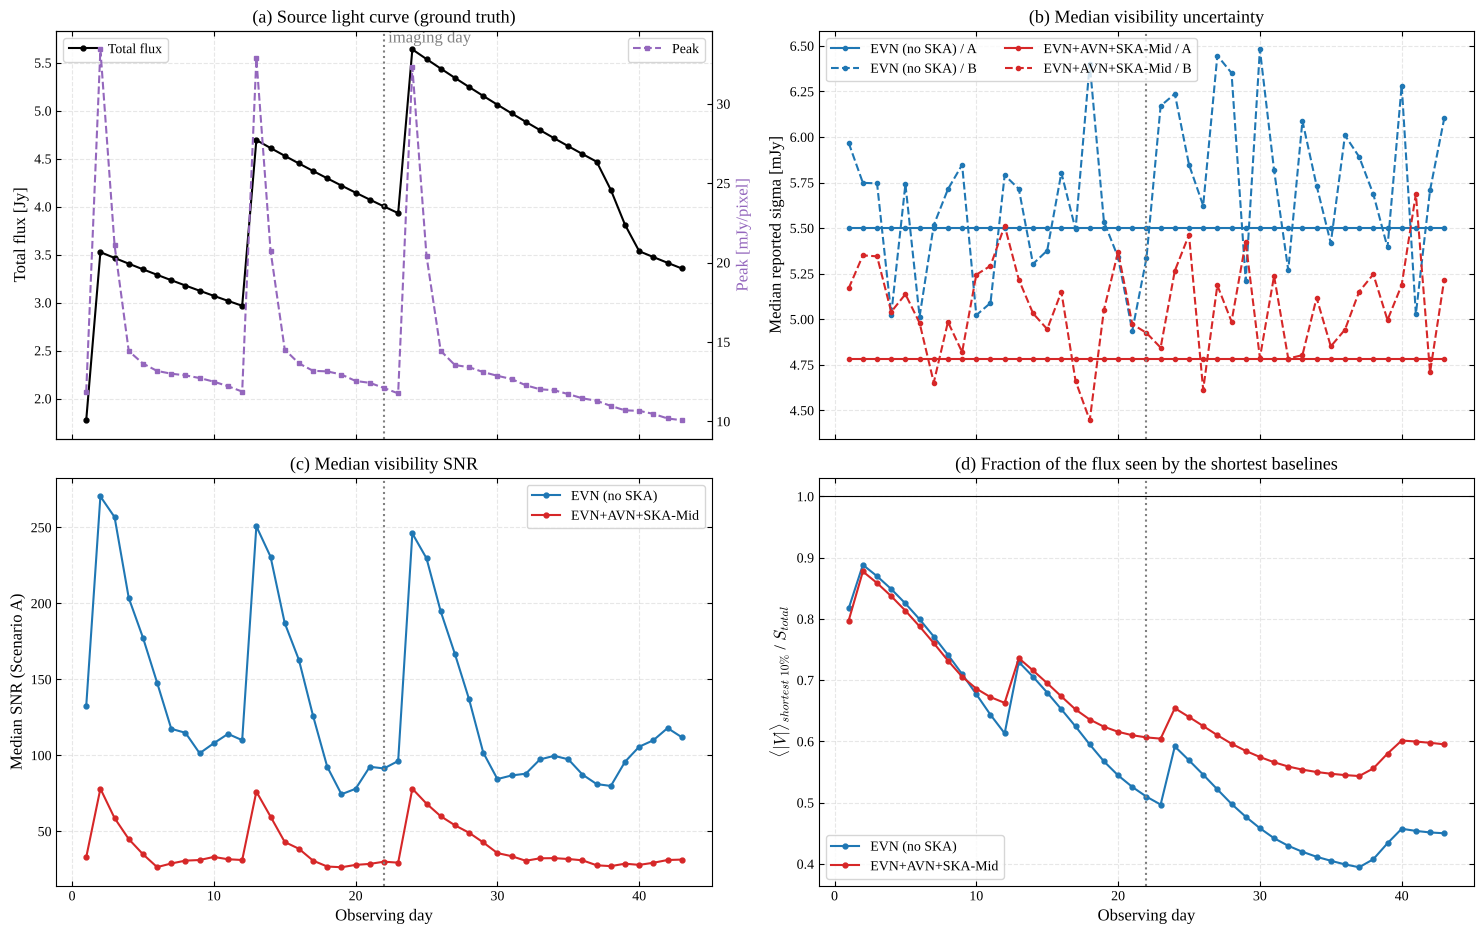

In [15]:
days = np.arange(1, N_DAYS + 1)
flux_t = np.array([TRUTH_FLUX[d] for d in days]); peak_t = np.array([TRUTH_PEAK[d] for d in days]) * 1e3

def per_day(a_key, s_key, fn):
    return np.array([fn(OBS[(a_key, s_key)][d], d) for d in days])

def short_amp_ratio(obs, d):
    uvd = uv_dist(obs); m = uvd <= np.percentile(uvd, 10)
    return np.abs(obs.data['vis'][m]).mean() / TRUTH_FLUX[d]

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), sharex=True)
ax = axes[0, 0]
ax.plot(days, flux_t, '-o', ms=3.5, color='k', label='Total flux')
ax.set_ylabel("Total flux [Jy]"); ax.set_title("(a) Source light curve (ground truth)")
axb = ax.twinx(); axb.plot(days, peak_t, '--s', ms=3, color='tab:purple', label='Peak')
axb.set_ylabel("Peak [mJy/pixel]", color='tab:purple'); axb.grid(False)
ax.legend(loc='upper left'); axb.legend(loc='upper right')

ax = axes[0, 1]
for a_key in ARRAYS:
    for s_key, ls in [("A", '-'), ("B", '--')]:
        ax.plot(days, per_day(a_key, s_key, lambda o, d: np.median(o.data['sigma']) * 1e3), ls, marker='o', ms=3,
                color=AR_COLOR[a_key], label=f"{a_key} / {s_key}")
ax.set_ylabel("Median reported sigma [mJy]"); ax.set_title("(b) Median visibility uncertainty"); ax.legend(ncol=2)

ax = axes[1, 0]
for a_key in ARRAYS:
    ax.plot(days, per_day(a_key, "A", lambda o, d: np.median(np.abs(o.data['vis']) / o.data['sigma'])),
            '-o', ms=3.5, color=AR_COLOR[a_key], label=a_key)
ax.set_ylabel("Median SNR (Scenario A)"); ax.set_xlabel("Observing day"); ax.set_title("(c) Median visibility SNR"); ax.legend()

ax = axes[1, 1]
for a_key in ARRAYS:
    ax.plot(days, per_day(a_key, "A", short_amp_ratio), '-o', ms=3.5, color=AR_COLOR[a_key], label=a_key)
ax.axhline(1, color='k', lw=0.8)
ax.set_ylabel(r"$\langle |V| \rangle_{shortest\ 10\%}$ / $S_{total}$"); ax.set_xlabel("Observing day")
ax.set_title("(d) Fraction of the flux seen by the shortest baselines"); ax.legend()
for ax in axes.flat:
    ax.axvline(IMAGING_DAY, color='gray', ls=':', lw=1.5)
axes[0, 0].text(IMAGING_DAY, axes[0, 0].get_ylim()[1], " imaging day", va='top', color='gray')
plt.tight_layout()
save_fig(fig, "08_campaign_evolution")

### 6.2 Visibility-amplitude "waterfall"

A way of seeing the source structure *evolve* without making a single image: the mean visibility amplitude in bins of $|uv|$ (vertical axis) for every day (horizontal axis), Scenario A. Each row is a given angular scale $\theta \sim 1/|uv|$:

- the **bottom rows** (short baselines) follow the large-scale flux (compare with the light curve);
- the **upper rows** (long baselines) are sensitive to the compact components and fluctuate strongly as blobs are ejected and travel.

EVN+AVN+SKA-Mid extends the picture to larger $|uv|$ (finer angular scales) than the EVN alone (no SKA).

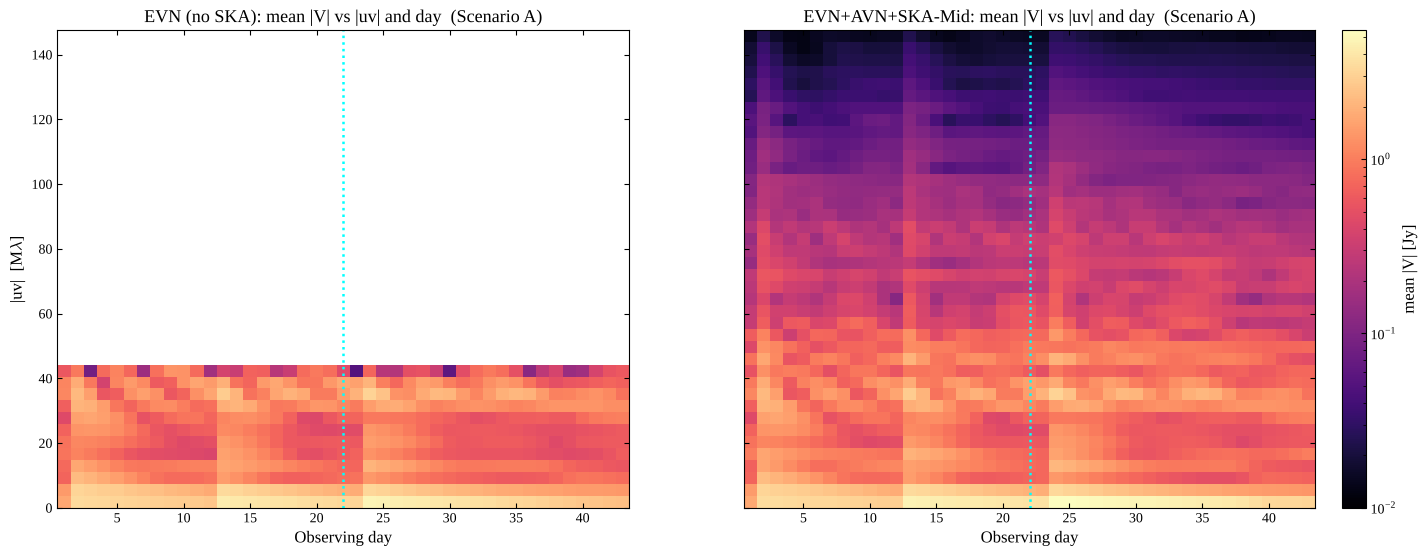

In [16]:
uv_max = max(uv_dist(OBS[("EVN+AVN+SKA-Mid", "A")][d]).max() for d in days)
edges = np.linspace(0, uv_max, 41)

def waterfall(a_key):
    W = np.full((len(edges) - 1, len(days)), np.nan)
    for j, d in enumerate(days):
        obs = OBS[(a_key, "A")][d]
        idx = np.digitize(uv_dist(obs), edges) - 1
        amp = np.abs(obs.data['vis'])
        for b in range(len(edges) - 1):
            m = idx == b
            if m.any(): W[b, j] = amp[m].mean()
    return W

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), sharey=True)
vmax = max(np.nanmax(waterfall(a)) for a in ARRAYS)
for ax, a_key in zip(axes, ARRAYS):
    W = waterfall(a_key)
    pcm = ax.pcolormesh(np.r_[days - 0.5, days[-1] + 0.5], edges, np.ma.masked_invalid(W), cmap='magma',
                        norm=LogNorm(vmin=1e-2, vmax=vmax))
    ax.axvline(IMAGING_DAY, color='cyan', ls=':', lw=1.8)
    ax.set_title(f"{a_key}: mean |V| vs |uv| and day  (Scenario A)")
    ax.set_xlabel("Observing day"); ax.grid(False)
axes[0].set_ylabel(r"|uv|  [M$\lambda$]")
fig.colorbar(pcm, ax=axes, fraction=0.025, pad=0.02).set_label("mean |V| [Jy]")
save_fig(fig, "09_visibility_waterfall")

### 6.3 Campaign summary table

Mean ± standard deviation over all days, per array and scenario, saved to `campaign_summary.csv`.

In [17]:
rows = []
for a_key in ARRAYS:
    for s_key in SCENARIOS:
        nv  = per_day(a_key, s_key, lambda o, d: len(o.data))
        snr = per_day(a_key, s_key, lambda o, d: np.median(np.abs(o.data['vis']) / o.data['sigma']))
        sig = per_day(a_key, s_key, lambda o, d: np.median(o.data['sigma']) * 1e3)
        short = per_day(a_key, s_key, short_amp_ratio)
        rows.append({"Array": a_key, "Scenario": s_key,
                     "N vis / day": f"{nv.mean():.0f} +- {nv.std():.0f}",
                     "Median SNR": f"{snr.mean():.1f} +- {snr.std():.1f}",
                     "Median sigma [mJy]": f"{sig.mean():.2f} +- {sig.std():.2f}",
                     "<|V|short>/S": f"{short.mean():.3f} +- {short.std():.3f}"})
df_campaign = pd.DataFrame(rows).set_index(["Array", "Scenario"])
display(df_campaign)
df_campaign.to_csv(f"{OUT_DIR}/campaign_summary.csv")
print(f"Truth total flux over the campaign: {flux_t.mean():.3f} +- {flux_t.std():.3f} Jy "
      f"(min {flux_t.min():.3f}, max {flux_t.max():.3f})")

N vis / day     Median SNR Median sigma [mJy]  \
Array           Scenario                                                 
EVN (no SKA)    A          3999 +- 0  133.8 +- 55.8       5.50 +- 0.00   
                B          3999 +- 0  133.9 +- 55.8       5.68 +- 0.42   
EVN+AVN+SKA-Mid A         15089 +- 0   38.6 +- 14.7       4.78 +- 0.00   
                B         15089 +- 0   38.6 +- 14.7       5.07 +- 0.26   

                            <|V|short>/S  
Array           Scenario                  
EVN (no SKA)    A         0.583 +- 0.147  
                B         0.581 +- 0.145  
EVN+AVN+SKA-Mid A         0.652 +- 0.090  
                B         0.645 +- 0.106

Truth total flux over the campaign: 4.115 +- 0.846 Jy (min 1.774, max 5.639)


## 7. Imaging of a single frame

Imaging every day multiplies the cost by 43 (this is what the full-campaign script `binary_jet_VLBI_campaign_full.py` does, and where it spends most of its ~2 days per scenario). We image **only `IMAGING_DAY`**, for the four datasets: EVN (no SKA) and EVN+AVN+SKA-Mid, Scenario A and B.

### 7.1 The imaging pipeline

Three rounds of RML imaging (`eh.imager.Imager`), the same recipe as in the full-campaign script (closure phases + amplitudes, then adding complex visibilities after a phase self-calibration):

| Round | Data terms | Regularisers | Notes |
|---|---|---|---|
| 1 | `cphase`, `amp` | `simple`, `flux`, `cm` | starts from a broad Gaussian prior with the true total flux; 150 iterations |
| 2 | `cphase`, `amp` | `tv`, `l1`, `flux`, `cm` | prior = round-1 image blurred by 0.3× the nominal resolution; 150 iterations |
| 3 | `cphase`, `amp`, `vis` | `tv`, `l1`, `flux`, `cm` | **after phase self-calibration** with the round-2 image; blurred by 0.2× the resolution; 200 iterations |

> **Why does round 1 use `simple` and not `tv`?** The total-variation regulariser has an ill-defined gradient on a perfectly smooth start image, and with `fast` FFTs and this high-SNR data the optimiser immediately ends with `J = nan` (*ABNORMAL termination*). The standard remedy, also used in the introductory notebook, is to start with the entropy-like `simple` term, and bring in `tv`/`l1` once the image has structure.
>
> **Why `flux = 10000`?** With SNR ~ 200 per visibility the $\chi^2$ terms are enormous, and a weak flux regulariser lets the total flux drift by tens of percent. A heavy weight keeps the reconstruction close to the true total flux (which, as in the original script, is assumed known: in practice it comes from the shortest baselines or from single-dish/connected-element data).

Self-calibration uses the *reconstruction itself* (never the true sky): it is the realistic, iterative "image → self-cal → image" loop of real VLBI.

> **Difference with the full-campaign script.** Here the imaging of the chosen day starts from a broad Gaussian prior. In the script, each day starts from the reconstruction of the previous day (blurred and rescaled to the true flux), the natural choice when imaging a movie frame by frame; the first day starts from the same Gaussian prior as here.

The reduced $\chi^2$ of every data term is recorded at each iteration, to follow the convergence of the fit (Section 8.2).

> **Systematic error budget (`SYS_NOISE = 0.02`).** The baselines between the phased SKA-Mid (`S5`, SEFD 3.1 Jy) and the other SKA-Mid dishes a few km away have SNR of up to ~8,600 (thermal sigma ~0.1 mJy), and the source *changes during the track*, so no single static image can fit those visibilities to within their thermal noise. Their amplitude $\chi^2$ (~2×10⁵) then dominates the objective function and, depending on the noise realisation, the optimiser stalls at the start image: in our tests the EVN+AVN+SKA-Mid reconstruction stayed at the Gaussian prior (NXCORR 0.24). Adding in quadrature a 2% fractional error to the sigma of the data used for imaging (`obs.add_fractional_noise`, the usual systematic error budget of VLBI imaging) caps the SNR at 50 and removes the problem. The data themselves, the UVFITS files and the data-domain statistics of Sections 5–6 are not modified.
>
> **Symmetry-breaking perturbation of the prior (`PRIOR_PERTURB = 0.10`).** The jet is point-symmetric (jet and counter-jet are mirror images through the core) and so is the centred Gaussian prior. Symmetric data acting on a symmetric image give symmetric gradients, so the optimiser leaves the start image only slowly, pushed by the noise: in our tests the amplitude $\chi^2$ stayed flat for the first ~45 iterations of round 1, and in one run it never moved (the EVN+AVN+SKA-Mid image stayed at the prior, NXCORR 0.24). Multiplying the prior by a 10% random perturbation (fixed seed, same total flux) shortens the plateau to 4–7 iterations. As a safety net, round 1 is repeated from a new perturbation (up to 3 attempts) if it does not lower the amplitude $\chi^2$ by at least 10%; the `Rounds OK` column and the round log report `retried` or `stalled` when this happens.
>
> **Iterations (150 / 150 / 200).** With 50 / 50 / 80 iterations the rounds stop far from convergence (the $\chi^2$ is still falling steeply). On the EVN+AVN+SKA-Mid data of the imaging day, the longer rounds raised the NXCORR from 0.50 to 0.90 at about twice the imaging time.

> **Cost:** ~2–3 min for each EVN (no SKA) dataset and ~4–6 min for each EVN+AVN+SKA-Mid dataset (self-calibrating 15 000 visibilities dominates), i.e. ~15 min in total on a single core.

In [18]:
# Editable imaging recipe. Each round: data terms, regularisers, iterations, optional blur of the start image
# (fraction of the array resolution) and optional self-calibration ('phase' or 'amp') using the previous image.
IMAGING_ROUNDS = [
    {'data_term': {'cphase': 50, 'amp': 50},
     'reg_term':  {'simple': 10, 'flux': 1e4, 'cm': 50},                  'maxit': 150},
    {'data_term': {'cphase': 80, 'amp': 80},
     'reg_term':  {'tv': 0.05, 'l1': 0.01, 'flux': 1e4, 'cm': 50},       'maxit': 150, 'blur_frac': 0.3},
    {'data_term': {'cphase': 100, 'amp': 100, 'vis': 30},
     'reg_term':  {'tv': 0.05, 'l1': 0.01, 'flux': 1e4, 'cm': 50},       'maxit': 200, 'blur_frac': 0.2, 'selfcal': 'phase'},
]
SYS_NOISE       = 0.02    # fractional systematic error added in quadrature to the thermal sigma, for imaging only
PRIOR_PERTURB   = 0.10    # random multiplicative perturbation of the Gaussian prior (symmetry breaking, see the text)
PRIOR_FWHM_FRAC = 0.4     # FWHM of the Gaussian prior, as a fraction of the FOV
RESTORE_BLUR    = 0.4     # final restoring blur, as a fraction of the clean beam (as in the full-campaign script)

class LoggedImager(eh.imager.Imager):
    # Imager that records the reduced chi^2 of every active data term at each iteration.
    def plotcur(self, imvec, **kwargs):
        if getattr(self, 'history', None) is not None:
            chi2 = self.make_chisq_dict(np.exp(imvec))          # the optimiser works on the log-image
            self.history.append({'round': self.round_id, 'iter': self._nit, **{k: float(v) for k, v in chi2.items()}})
        super().plotcur(imvec, **kwargs)

def perturbed_prior(prior, seed):
    # The jet is point-symmetric, and so is a centred Gaussian prior. Symmetric data acting on a symmetric image give
    # symmetric gradients, so the optimiser leaves the start image only slowly, driven by the noise: an amplitude-chi^2
    # plateau of ~50 iterations, and sometimes a complete stall at the prior. A small random perturbation of the prior
    # (fixed seed, total flux preserved) breaks the symmetry.
    out = prior.copy()
    rng = np.random.default_rng(seed)
    out.imvec = prior.imvec * np.exp(PRIOR_PERTURB * rng.standard_normal(prior.imvec.size))
    out.imvec *= prior.total_flux() / out.imvec.sum()
    return out

def run_imaging_pipeline(obs, total_flux, rounds, ttype=TTYPE, verbose=True, history=None):
    # Multi-round RML imaging with optional self-calibration. Returns (image, final_obs, round_log, imaging_obs).
    # If `history` is a list, the reduced chi^2 of each data term is appended to it at every iteration.
    # The data used for imaging (and self-calibration) carry a systematic error budget of SYS_NOISE x |V|.
    # Stall guard: if round 1 does not lower the amplitude chi^2 by at least 10%, it is repeated from a new
    # perturbation of the prior (up to 3 attempts).
    if SYS_NOISE > 0:
        with quiet():
            obs = obs.add_fractional_noise(SYS_NOISE)
    empty = eh.image.make_square(obs, NPIX, OBSERVATION_FOV * RAD)
    sz = PRIOR_FWHM_FRAC * OBSERVATION_FOV * RAD
    prior = empty.add_gauss(total_flux, (sz, sz, 0, 0, 0))
    out = prior
    res, cur, log = obs.res(), obs, []
    for k, rnd in enumerate(rounds, 1):
        t0 = time.time()
        if rnd.get('selfcal'):
            with no_plot(), quiet():
                cur = self_cal(obs, out, method=rnd['selfcal'], ttype=ttype)
        n_attempts = 3 if k == 1 else 1
        for attempt in range(n_attempts):
            if k == 1:
                init = perturbed_prior(prior, seed=attempt)
            else:
                bf = rnd.get('blur_frac', 0.0)
                init = out.blur_circ(res * bf) if bf > 0 else out
            n_hist = len(history) if history is not None else 0
            with no_plot(), quiet() as buf:
                imgr = LoggedImager(cur, init, init, total_flux, data_term=rnd['data_term'],
                                    reg_term=rnd['reg_term'], maxit=rnd['maxit'], ttype=ttype, show_updates=False)
                imgr.history, imgr.round_id = history, k
                new = imgr.make_image(clipfloor=1e-9)
                c0 = imgr.make_chisq_dict(init.imvec).get('amp', np.nan)
                c1 = imgr.make_chisq_dict(new.imvec).get('amp', np.nan)
            stalled = k == 1 and 'amp' in rnd['data_term'] and c1 > 0.9 * c0
            if not stalled or attempt == n_attempts - 1:
                break
            if history is not None:
                del history[n_hist:]
            if verbose:
                print(f"      round {k}: amplitude chi^2 did not decrease ({c0:.0f} -> {c1:.0f}); "
                      f"retrying from a new perturbation of the prior")
        out = new
        status = ("ABNORMAL" if "ABNORMAL" in buf.getvalue() else
                  "stalled" if stalled else "retried" if attempt > 0 else "ok")
        log.append({'round': k, 'terms': '+'.join(rnd['data_term']), 'status': status, 'seconds': time.time() - t0})
        if verbose:
            print(f"      round {k}: {'+'.join(rnd['data_term']):<18} selfcal={rnd.get('selfcal', '-'):<6} "
                  f"-> {status:<8} ({time.time() - t0:5.1f} s)  flux = {out.total_flux():.3f} Jy")
    return out, cur, log, obs

# ------------------------------- metrics --------------------------------------------------------
def calc_rmse(d_true, d_rec):  return float(np.sqrt(np.mean((d_true - d_rec) ** 2)))
def calc_nrmse(d_rec, d_true):
    a, b = d_rec / d_rec.sum(), d_true / d_true.sum()
    return float(np.sqrt(np.mean((a - b) ** 2)) / np.sqrt(np.mean(b ** 2)))
def calc_nxcorr(d_true, d_rec):
    norm = np.sqrt(np.sum(d_true ** 2) * np.sum(d_rec ** 2))
    return float(np.sum(d_true * d_rec) / norm) if norm > 0 else 0.0
def calc_ssim(d_true, d_rec):
    return float(ssim(d_true, d_rec, data_range=d_true.max())) if HAS_SSIM else np.nan
def calc_dynamic_range(d_rec, d_ref):
    # peak / rms of the reconstruction where the reference (truth restored with the same beam) is below 1% of its
    # peak, i.e. in the region where any emission is an artefact. (An empty corner of the image is useless here:
    # after the imager's clipfloor it is exactly zero, and the ratio diverges.)
    off = d_ref < 0.01 * d_ref.max()
    rms = np.std(d_rec[off])
    return float(d_rec.max() / rms) if rms > 0 else np.inf
def calc_chi2_amp(obs, im_rec):
    try:
        sim = im_rec.observe_same_nonoise(obs, ttype=TTYPE)
        a_o, a_s = obs.unpack(['amp', 'sigma']), sim.unpack(['amp'])
        m = a_o['sigma'] > 0
        return float(np.sum(((a_o['amp'][m] - a_s['amp'][m]) / a_o['sigma'][m]) ** 2) / np.sum(m))
    except Exception:
        return np.nan
def calc_chi2_cphase(obs, im_rec):
    try:
        with quiet():
            o = obs.copy(); o.add_cphase(count='min')
            sim = im_rec.observe_same_nonoise(obs, ttype=TTYPE); sim.add_cphase(count='min')
        co, cs = o.cphase, sim.cphase
        if len(co) != len(cs): return np.nan
        diff = np.angle(np.exp(1j * np.radians(co['cphase'])) * np.exp(-1j * np.radians(cs['cphase'])))
        m = co['sigmacp'] > 0
        return float(np.sum((diff[m] / np.radians(co['sigmacp'][m])) ** 2) / np.sum(m))
    except Exception:
        return np.nan

print("Imaging recipe and metrics defined.")

Imaging recipe and metrics defined.


### 7.2 Run the four reconstructions

For each dataset we: (1) run the pipeline, (2) **align** the reconstruction with the ground truth (closure phases do not fix the absolute position of the source, so the image can be arbitrarily shifted), and (3) convolve it with the fitted clean beam (`RESTORE_BLUR` × beam), the standard "restored" image. Metrics are computed on the restored image, against the ground-truth frame of `IMAGING_DAY`.

In [19]:
ZBL = TRUTH_IM.total_flux()
RECON, HIST = {}, {}
t_img = time.time()
print(f"Imaging day {IMAGING_DAY}: true total flux = {ZBL:.3f} Jy\n")

for a_key in ARRAYS:
    for s_key in SCENARIOS:
        key = (a_key, s_key)
        obs = OBS[key][IMAGING_DAY]
        print(f"=== {a_key} / Scenario {s_key}   ({len(obs.data)} visibilities) ===")
        t0 = time.time()
        HIST[key] = []
        raw, obs_cal, log, obs_sys = run_imaging_pipeline(obs, ZBL, IMAGING_ROUNDS, history=HIST[key])
        beam = obs.fit_beam()
        aligned = TRUTH_IM.align_images([raw])[0][0]
        restored = aligned.blur_gauss(beam, RESTORE_BLUR)
        RECON[key] = dict(raw=raw, aligned=aligned, restored=restored, beam=beam, obs_cal=obs_cal, obs_sys=obs_sys,
                          log=log, seconds=time.time() - t0)
        print(f"      done in {time.time() - t0:.0f} s\n")

print(f"All reconstructions done in {(time.time() - t_img) / 60:.1f} min.")

Imaging day 22: true total flux = 4.002 Jy

=== EVN (no SKA) / Scenario A   (3999 visibilities) ===


      round 1: cphase+amp         selfcal=-      -> ok       ( 70.7 s)  flux = 4.627 Jy


      round 2: cphase+amp         selfcal=-      -> ok       ( 24.3 s)  flux = 4.702 Jy


      round 3: cphase+amp+vis     selfcal=phase  -> ok       ( 31.1 s)  flux = 4.453 Jy


      done in 126 s

=== EVN (no SKA) / Scenario B   (3999 visibilities) ===


      round 1: cphase+amp         selfcal=-      -> ok       ( 74.1 s)  flux = 4.525 Jy


... (7 outputs left out)

      round 1: cphase+amp         selfcal=-      -> ok       ( 96.3 s)  flux = 4.042 Jy


      round 2: cphase+amp         selfcal=-      -> ok       ( 99.2 s)  flux = 4.074 Jy


      round 3: cphase+amp+vis     selfcal=phase  -> ok       (252.2 s)  flux = 4.163 Jy


      done in 448 s

All reconstructions done in 18.3 min.


### 7.3 Dirty image vs. restored images

Top row = EVN (no SKA), bottom row = EVN+AVN+SKA-Mid. **Left:** the dirty image of the Scenario-A data (the data Fourier-transformed directly, i.e. the true sky convolved with the dirty beam, side-lobes and all), in mJy per dirty beam and with its own colour scale. **Centre and right:** the restored RML reconstructions for Scenario A and B. White ellipse = clean beam. All panels share the same colour scale.

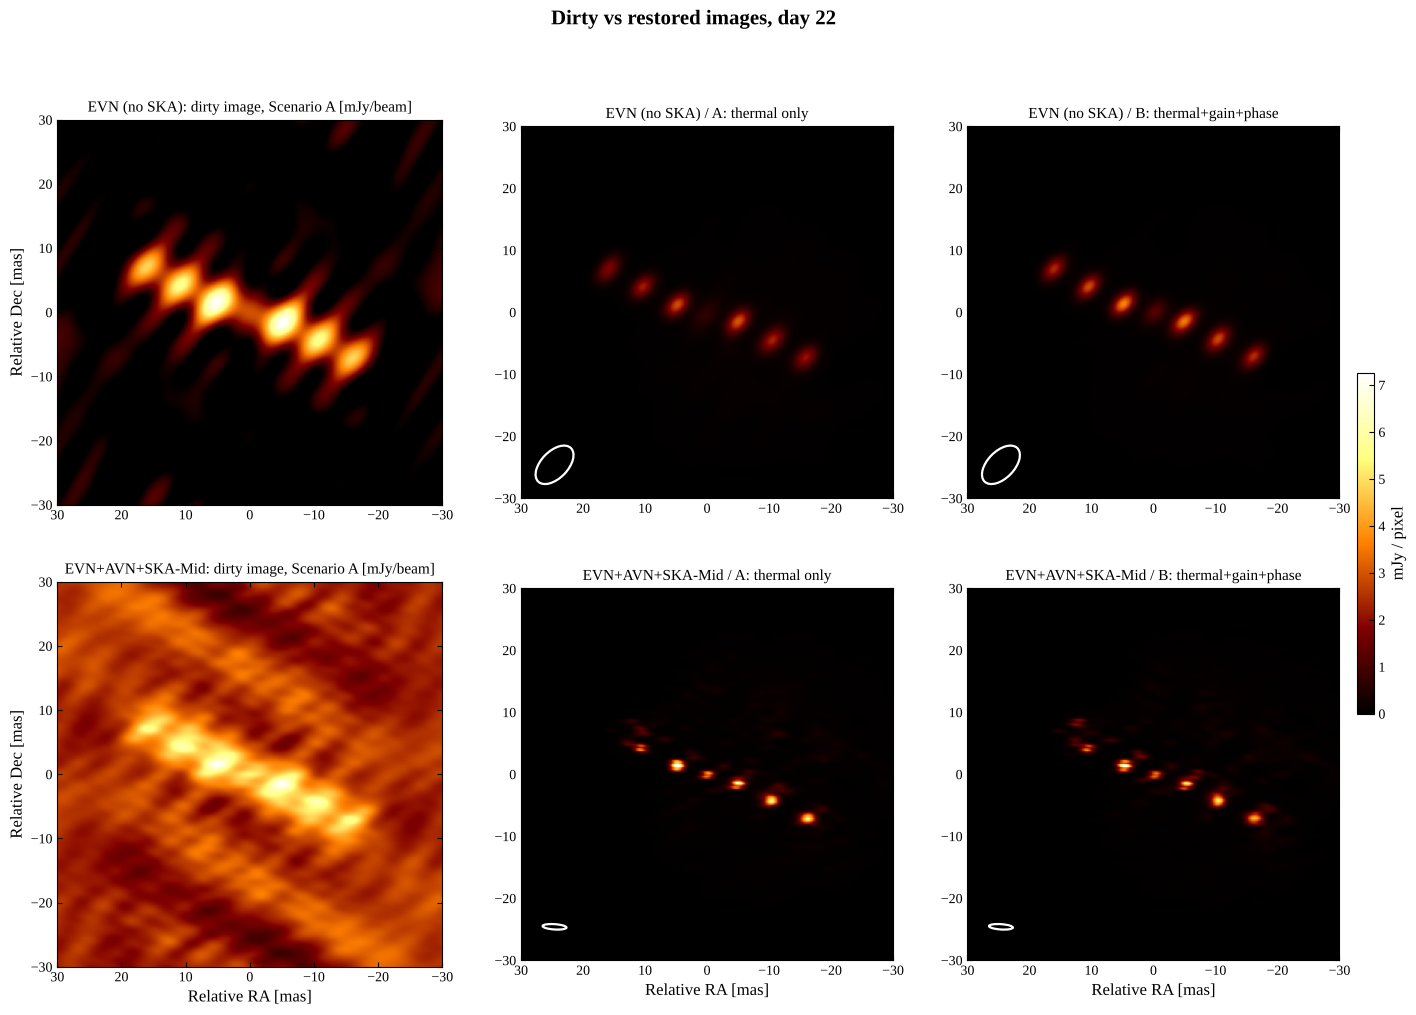

In [20]:
d_truth_mJy = TRUTH_IM.imarr() * 1000.0
VMAX_MJY = d_truth_mJy.max() * 0.6

def draw_beam(ax, beam, color='white'):
    # clean-beam ellipse in the lower-left corner of an image axis. RA increases to the left, so a position angle
    # measured from north through east (ehtim's convention) is a rotation of -PA in these data coordinates.
    bmaj, bmin, pa = [beam[0] / RAD / 1e3, beam[1] / RAD / 1e3, beam[2]]
    ax.add_patch(Ellipse((0.82 * LIMIT_MAS, -0.82 * LIMIT_MAS), width=bmin, height=bmaj,
                         angle=-np.degrees(pa), facecolor='none', edgecolor=color, lw=1.6))

def show_image(ax, arr_mJy, title, beam=None, vmax=VMAX_MJY, cmap='afmhot'):
    im = ax.imshow(arr_mJy, origin='upper', cmap=cmap, extent=EXTENT_MAS, vmin=0, vmax=vmax)   # row 0 = north
    ax.set_xlim(LIMIT_MAS, -LIMIT_MAS); ax.set_ylim(-LIMIT_MAS, LIMIT_MAS); ax.grid(False)
    ax.set_title(title, fontsize=11)
    if beam is not None: draw_beam(ax, beam)
    return im

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
for r, a_key in enumerate(ARRAYS):
    obs = OBS[(a_key, "A")][IMAGING_DAY]
    with quiet():
        dirty = obs.dirtyimage(NPIX, OBSERVATION_FOV * RAD)
        dbeam = obs.dirtybeam(NPIX, OBSERVATION_FOV * RAD)
    # both are divided by the same (ill-conditioned) sum of the beam in ehtim: dividing by the beam's central value
    # cancels it and gives the dirty image in Jy per dirty beam
    dd = dirty.imarr() / dbeam.imarr()[NPIX // 2, NPIX // 2] * 1000.0
    show_image(axes[r, 0], np.clip(dd, 0, None), f"{a_key}: dirty image, Scenario A [mJy/beam]", vmax=dd.max())
    for c, s_key in enumerate(SCENARIOS, start=1):
        R = RECON[(a_key, s_key)]
        im = show_image(axes[r, c], R['restored'].imarr() * 1000.0, f"{a_key} / {SCENARIOS[s_key]['label']}", R['beam'])
for ax in axes[1]: ax.set_xlabel("Relative RA [mas]")
for ax in axes[:, 0]: ax.set_ylabel("Relative Dec [mas]")
fig.colorbar(im, ax=axes[:, 1:], fraction=0.02, pad=0.02).set_label("mJy / pixel")
fig.suptitle(f"Dirty vs restored images, day {IMAGING_DAY}", fontsize=15, fontweight='bold')
save_fig(fig, "10_dirty_vs_restored")

### 7.4 Ground truth vs. reconstructions, and residuals

Top: ground truth and the four restored reconstructions on a common scale. Bottom: the residual **restored − truth** (mJy/pixel, diverging colour map). The first bottom panel shows the truth convolved with the EVN+AVN+SKA-Mid beam, i.e. what a *perfect* reconstruction at that resolution would look like. Note that the residual against the *unblurred* truth includes the unavoidable loss of fine detail, so a perfect result does not give zero.

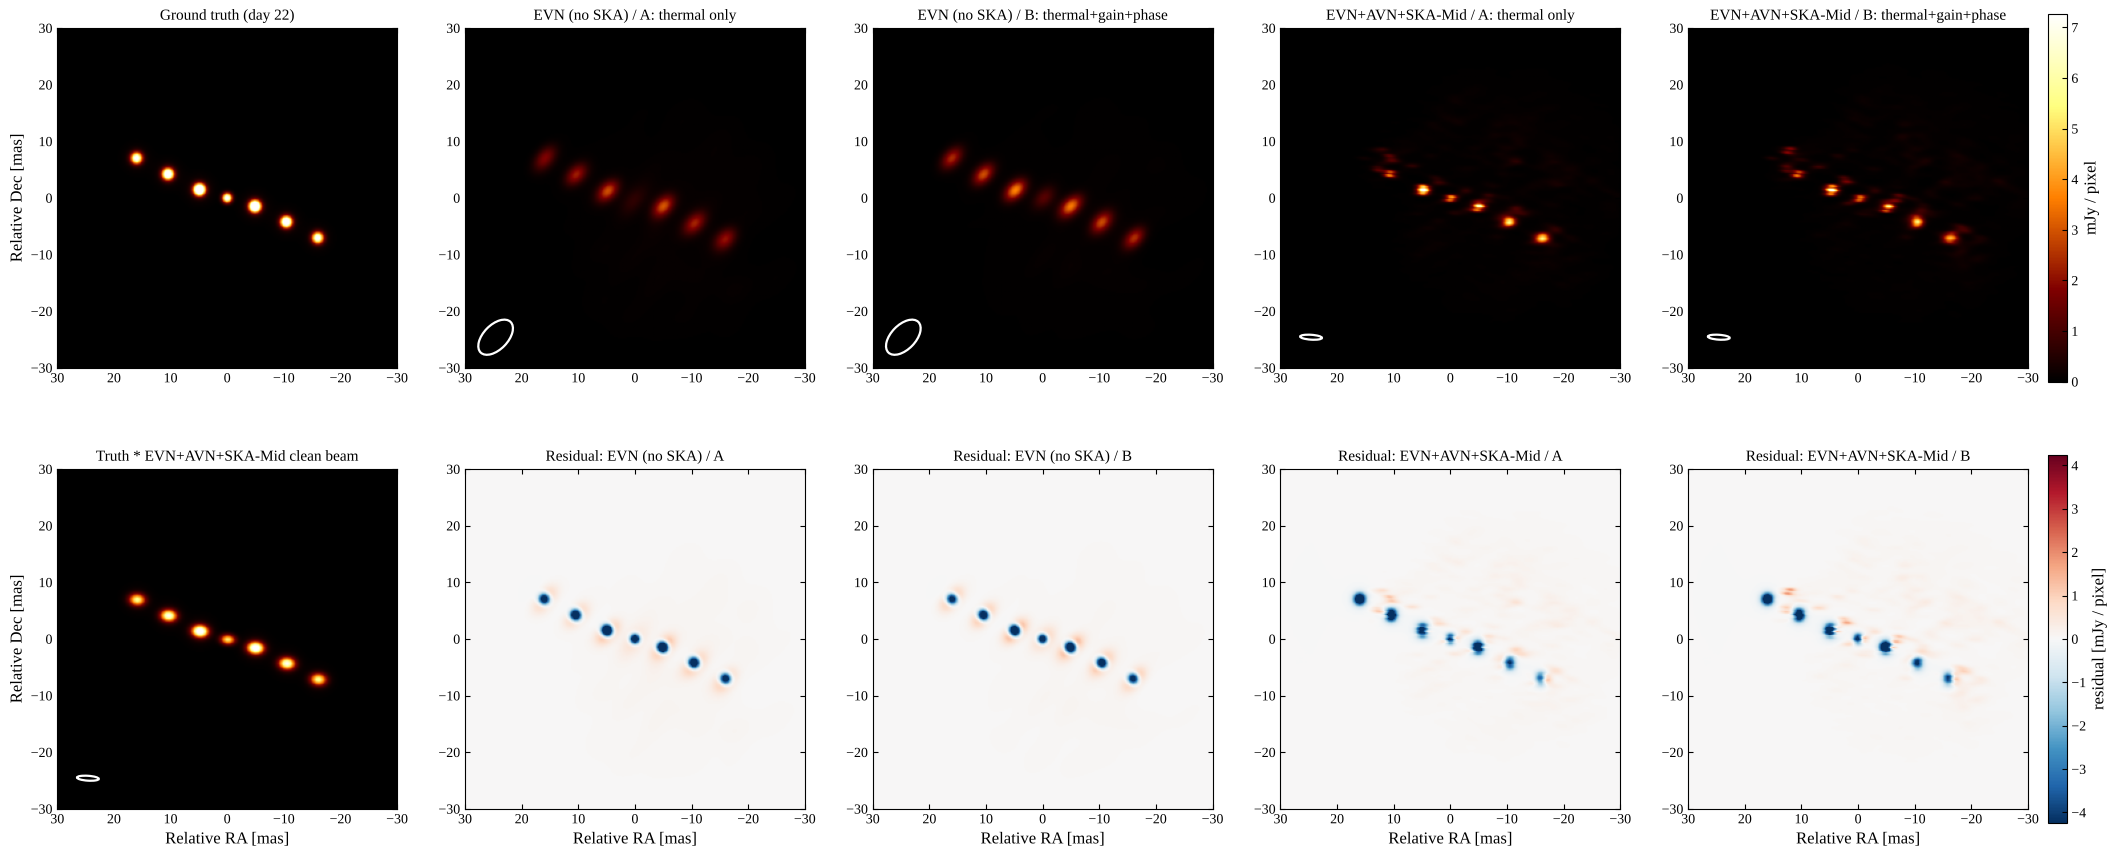

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(26, 10.5))
im = show_image(axes[0, 0], d_truth_mJy, f"Ground truth (day {IMAGING_DAY})")
truth_blur = TRUTH_IM.blur_gauss(RECON[("EVN+AVN+SKA-Mid", "A")]['beam'], RESTORE_BLUR)
show_image(axes[1, 0], truth_blur.imarr() * 1000.0, "Truth * EVN+AVN+SKA-Mid clean beam", RECON[("EVN+AVN+SKA-Mid", "A")]['beam'])

res_lim = 0.35 * d_truth_mJy.max()
c = 1
for a_key in ARRAYS:
    for s_key in SCENARIOS:
        R = RECON[(a_key, s_key)]
        show_image(axes[0, c], R['restored'].imarr() * 1000.0, f"{a_key} / {SCENARIOS[s_key]['label']}", R['beam'])
        resid = (R['restored'].imarr() - TRUTH_IM.imarr()) * 1000.0
        imr = axes[1, c].imshow(resid, origin='upper', cmap='RdBu_r', extent=EXTENT_MAS, vmin=-res_lim, vmax=res_lim)
        axes[1, c].set_xlim(LIMIT_MAS, -LIMIT_MAS); axes[1, c].set_ylim(-LIMIT_MAS, LIMIT_MAS); axes[1, c].grid(False)
        axes[1, c].set_title(f"Residual: {a_key} / {s_key}", fontsize=11)
        c += 1
for ax in axes[1]: ax.set_xlabel("Relative RA [mas]")
for ax in axes[:, 0]: ax.set_ylabel("Relative Dec [mas]")
fig.colorbar(im,  ax=axes[0, :], fraction=0.012, pad=0.01).set_label("mJy / pixel")
fig.colorbar(imr, ax=axes[1, :], fraction=0.012, pad=0.01).set_label("residual [mJy / pixel]")
save_fig(fig, "11_truth_vs_reconstructions")

### 7.5 Integrated profile along the jet axis

Collapsing the image along Dec gives the flux distribution along the RA axis (the main direction of the ejecta). It is a compact way of checking whether the reconstructions recover the *positions and relative strengths of the components*, independently of the 2-D morphology.

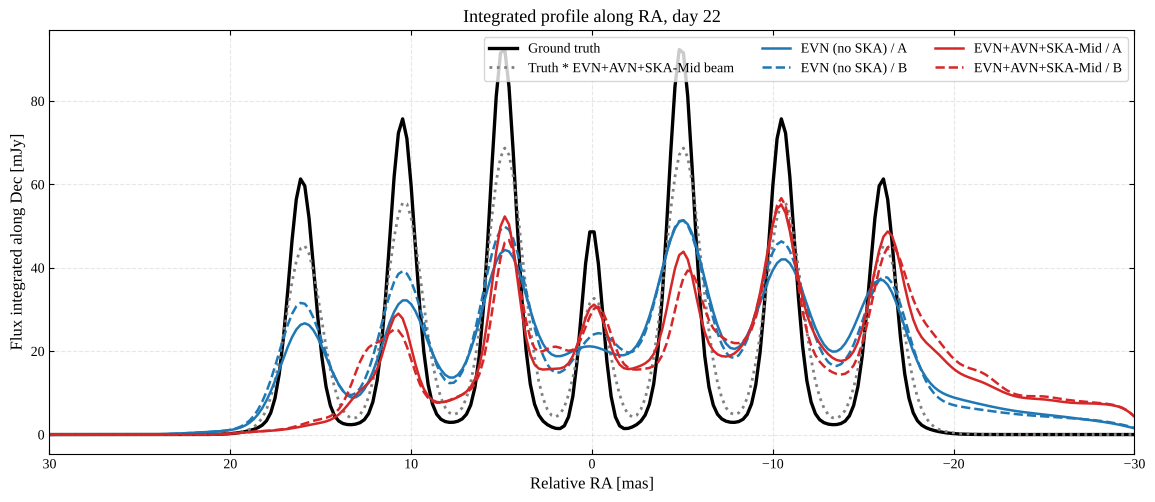

In [22]:
x_mas = np.linspace(LIMIT_MAS, -LIMIT_MAS, NPIX)
prof = lambda im: im.imarr().sum(axis=0) * 1000.0         # mJy per RA column (integrated over Dec)

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(x_mas, prof(TRUTH_IM), color='k', lw=2.4, label='Ground truth')
ax.plot(x_mas, prof(truth_blur), color='gray', lw=2, ls=':', label='Truth * EVN+AVN+SKA-Mid beam')
sty = {("EVN (no SKA)", "A"): ('tab:blue', '-'), ("EVN (no SKA)", "B"): ('tab:blue', '--'),
       ("EVN+AVN+SKA-Mid", "A"): ('tab:red', '-'), ("EVN+AVN+SKA-Mid", "B"): ('tab:red', '--')}
for key, (col, ls) in sty.items():
    ax.plot(x_mas, prof(RECON[key]['restored']), color=col, ls=ls, lw=1.8, label=f"{key[0]} / {key[1]}")
ax.set_xlim(LIMIT_MAS, -LIMIT_MAS)
ax.set_xlabel("Relative RA [mas]"); ax.set_ylabel("Flux integrated along Dec [mJy]")
ax.set_title(f"Integrated profile along RA, day {IMAGING_DAY}"); ax.legend(ncol=3)
save_fig(fig, "12_integrated_profile")

## 8. Metrics and summary

### 8.1 Image-fidelity metrics

Computed on the *restored* image against the ground truth of the imaging day:

| Metric | Meaning | Better |
|---|---|---|
| **RMSE** [mJy/px] | pixel-by-pixel intensity error | lower |
| **NRMSE** | RMSE of the unit-flux-normalised images, relative to the truth's RMS | lower |
| **NXCORR** | normalised cross-correlation (structural similarity, insensitive to flux scaling) | → 1 |
| **NXCORR (vs blurred truth)** | the same, against the truth convolved with *that array's* beam: separates "lost resolution" from "wrong structure" | → 1 |
| **SSIM** | structural similarity index (scikit-image) | → 1 |
| **Dynamic range** | peak / RMS of the restored image where the truth (restored with the same beam) has no emission (< 1% of its peak) | higher |
| **Flux ratio** | reconstructed / true total flux | → 1 |
| **χ²(cphase), χ²(amp)** | fit of the final image to the closure phases (raw data) and amplitudes (self-calibrated data), with the thermal + 2% systematic error budget used for imaging; reduced, so ≈ 1 would be a perfect fit | → 1 |

In [23]:
def chi2_amp_quiet(obs, im):
    with quiet():
        return calc_chi2_amp(obs, im)

rows = []
d_true = TRUTH_IM.imarr()
for key, R in RECON.items():
    a_key, s_key = key
    d_rec = R['restored'].imarr()
    d_tb = TRUTH_IM.blur_gauss(R['beam'], RESTORE_BLUR).imarr()
    rows.append({
        "Dataset": f"{a_key} / {s_key}",
        "RMSE [mJy/px]": calc_rmse(d_true, d_rec) * 1e3,
        "NRMSE": calc_nrmse(d_rec, d_true),
        "NXCORR": calc_nxcorr(d_true, d_rec),
        "NXCORR (vs blurred truth)": calc_nxcorr(d_tb, d_rec),
        "SSIM": calc_ssim(d_true, d_rec),
        "Dynamic range": calc_dynamic_range(d_rec, d_tb),
        "Flux ratio": R['raw'].total_flux() / ZBL,
        "chi2 cphase": calc_chi2_cphase(R['obs_sys'], R['raw']),
        "chi2 amp": chi2_amp_quiet(R['obs_cal'], R['raw']),
        "Rounds OK": f"{sum(l['status'] in ('ok', 'retried') for l in R['log'])}/{len(R['log'])}",
        "Time [s]": R['seconds'],
    })
df_metrics = pd.DataFrame(rows).set_index("Dataset")
display(df_metrics.round(3))
df_metrics.to_csv(f"{OUT_DIR}/imaging_metrics_day{IMAGING_DAY:02d}.csv")

,RMSE [mJy/px],NRMSE,NXCORR,NXCORR (vs blurred truth),SSIM,Dynamic range,Flux ratio,chi2 cphase,chi2 amp,Rounds OK,Time [s]
Dataset,,,,,,,,,,,
EVN (no SKA) / A,0.376,0.724,0.808,0.976,0.895,105.557,1.113,50.170,124.787,3/3,126.463
EVN (no SKA) / B,0.339,0.668,0.846,0.989,0.919,172.246,1.142,20.271,72.877,3/3,159.051
EVN+AVN+SKA-Mid / A,0.332,0.622,0.858,0.851,0.877,141.224,1.030,76.524,172.941,3/3,366.245
EVN+AVN+SKA-Mid / B,0.358,0.673,0.818,0.834,0.873,109.725,1.040,61.046,138.762,3/3,448.002


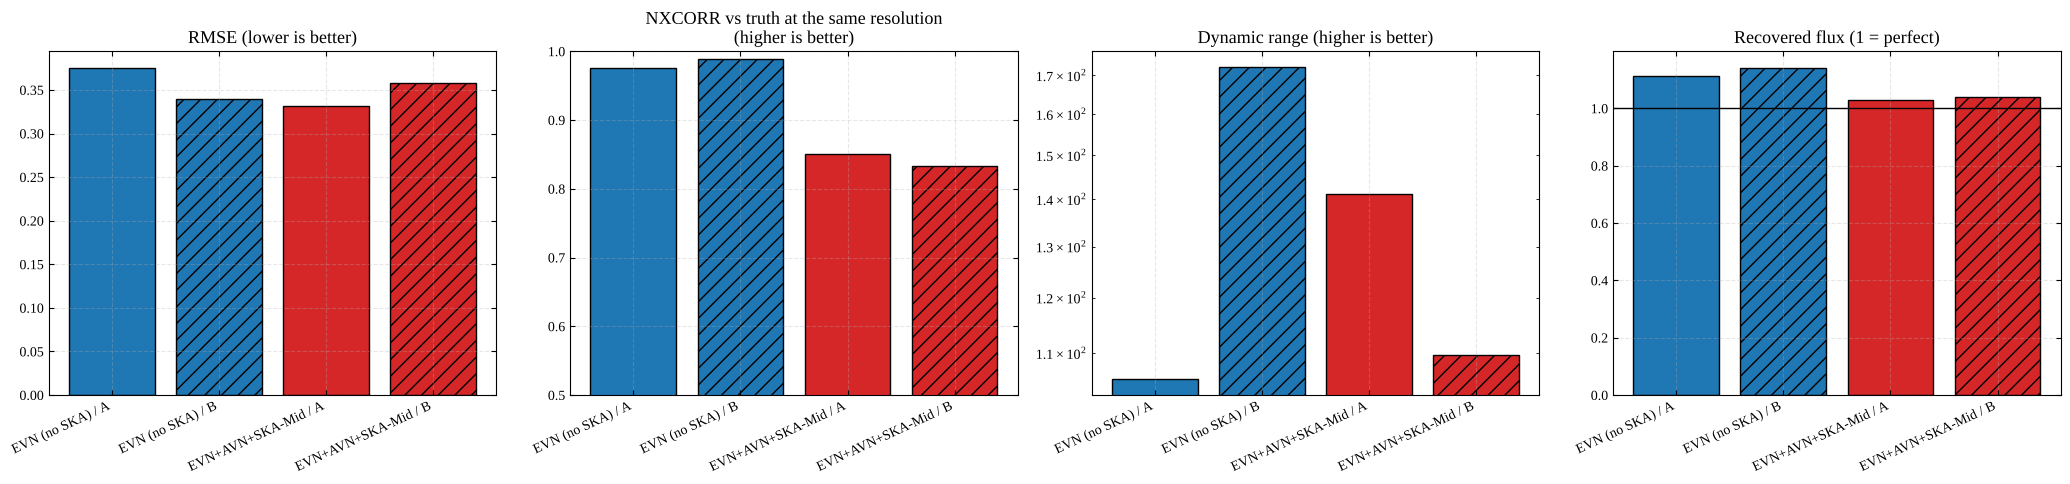

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(21, 5.0))
labels = list(df_metrics.index)
colors = [AR_COLOR[l.split(' / ')[0]] for l in labels]
hatch  = ['' if l.endswith('A') else '//' for l in labels]
for ax, col, title in zip(axes, ["RMSE [mJy/px]", "NXCORR (vs blurred truth)", "Dynamic range", "Flux ratio"],
                          ["RMSE (lower is better)", "NXCORR vs truth at the same resolution\n(higher is better)",
                           "Dynamic range (higher is better)", "Recovered flux (1 = perfect)"]):
    bars = ax.bar(range(len(labels)), df_metrics[col].values, color=colors, edgecolor='k')
    for b, h in zip(bars, hatch): b.set_hatch(h)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=25, ha='right'); ax.set_title(title)
    if col == "Flux ratio": ax.axhline(1, color='k', lw=1)
    if col.startswith("NXCORR"): ax.set_ylim(min(0.5, np.nanmin(df_metrics[col].values) - 0.05), 1.0)
    if col == "Dynamic range": ax.set_yscale("log")
plt.tight_layout()
save_fig(fig, "13_metrics_summary")

### 8.2 Convergence of the data fit

Reduced $\chi^2$ of each data term over the iterations of the three imaging rounds, per dataset (iterations are cumulative; vertical lines mark the start of rounds 2 and 3; the dotted line is $\chi^2 = 1$, a fit to within the thermal noise). The terms of round 3 are computed on the phase-self-calibrated data. A curve that keeps decreasing at the end of a round means that the round stopped before convergence (`maxit`); a curve that flattens well above 1 means that the image cannot explain the data, either because of residual calibration errors or because a single static image cannot reproduce a source that changes during the track.

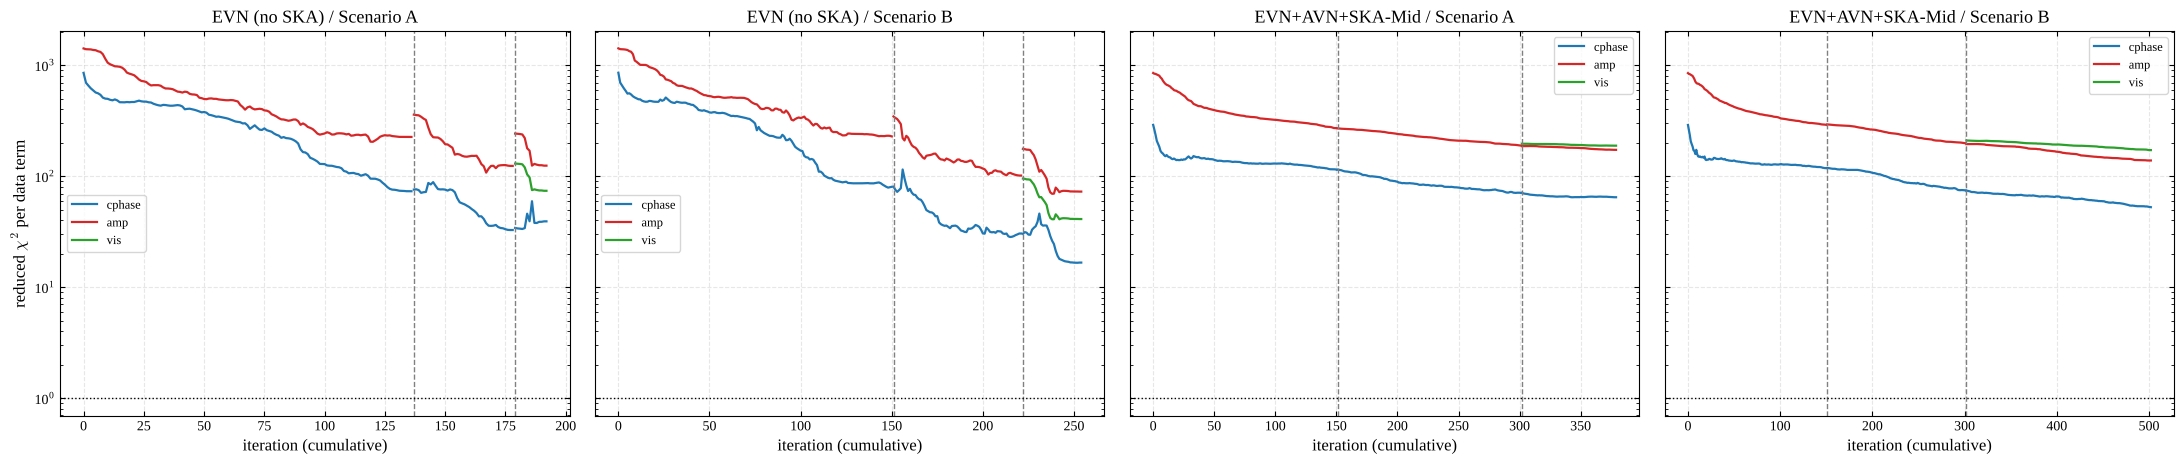

cphase     amp     vis
Dataset             round                        
EVN (no SKA) / A    1       73.38  226.32     NaN
                    2       32.81  124.07     NaN
                    3       39.28  124.75   74.05
EVN (no SKA) / B    1       80.44  228.92     NaN
                    2       30.52  101.57     NaN
                    3       16.70   72.83   41.20
EVN+AVN+SKA-Mid / A 1      114.80  271.58     NaN
                    2       70.88  189.11     NaN
                    3       64.78  173.14  188.81
EVN+AVN+SKA-Mid / B 1      118.63  290.40     NaN
                    2       74.48  198.44     NaN
                    3       52.72  138.87  172.17

In [25]:
TERMS = ['cphase', 'amp', 'vis']
T_COLORS = dict(zip(TERMS, ['tab:blue', 'tab:red', 'tab:green']))
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), sharey=True)
chi2_rows = []
for ax, key in zip(axes, RECON):
    h = HIST[key]; off, edges, labelled = 0, [], set()
    for r in sorted({x['round'] for x in h}):
        rec = [x for x in h if x['round'] == r]
        xs = np.array([off + x['iter'] for x in rec])
        for t in TERMS:
            if t in rec[0]:
                ax.semilogy(xs, [x[t] for x in rec], color=T_COLORS[t], lw=1.6, label=None if t in labelled else t)
                labelled.add(t)
        chi2_rows.append({'Dataset': f"{key[0]} / {key[1]}", 'round': r, **{t: rec[-1].get(t, np.nan) for t in TERMS}})
        off = xs.max() + 1; edges.append(off)
    for e in edges[:-1]: ax.axvline(e, color='gray', ls='--', lw=1)
    ax.axhline(1, color='k', ls=':', lw=1)
    ax.set_title(f"{key[0]} / Scenario {key[1]}"); ax.set_xlabel("iteration (cumulative)"); ax.legend(fontsize=9)
axes[0].set_ylabel(r"reduced $\chi^2$ per data term")
plt.tight_layout()
save_fig(fig, "14_chi2_convergence")
df_chi2 = pd.DataFrame(chi2_rows).set_index(['Dataset', 'round'])
display(df_chi2.round(2))

### 8.3 Putting data statistics and image quality together

The real value of the campaign-wide simulation is to relate **what the array measures** (Sections 5–6) with **what you can reconstruct** (Section 7). The cell below prints an automatic reading of the numbers of *this* run.

In [26]:
def pick(a, s, col): return df_metrics.loc[f"{a} / {s}", col]

print("-" * 78)
print(f"Resolution gain from adding the AVN + SKA-Mid (fitted beam major axis): "
      f"{RECON[('EVN (no SKA)','A')]['beam'][0]/RAD/1e3:.1f} mas -> {RECON[('EVN+AVN+SKA-Mid','A')]['beam'][0]/RAD/1e3:.1f} mas")
print(f"Visibilities: EVN (no SKA) = {len(OBS[('EVN (no SKA)','A')][IMAGING_DAY].data)},  "
      f"EVN+AVN+SKA-Mid = {len(OBS[('EVN+AVN+SKA-Mid','A')][IMAGING_DAY].data)}")
for a in ARRAYS:
    print(f"{a:8s}: Scenario A -> B:  NXCORR {pick(a,'A','NXCORR'):.3f} -> {pick(a,'B','NXCORR'):.3f},  "
          f"RMSE {pick(a,'A','RMSE [mJy/px]'):.3f} -> {pick(a,'B','RMSE [mJy/px]'):.3f} mJy/px")
for s in SCENARIOS:
    print(f"Scenario {s}: EVN (no SKA) -> EVN+AVN+SKA-Mid:  NXCORR {pick('EVN (no SKA)',s,'NXCORR'):.3f} -> {pick('EVN+AVN+SKA-Mid',s,'NXCORR'):.3f},  "
          f"NXCORR vs blurred truth {pick('EVN (no SKA)',s,'NXCORR (vs blurred truth)'):.3f} -> {pick('EVN+AVN+SKA-Mid',s,'NXCORR (vs blurred truth)'):.3f}")
print(f"Closure-phase error, robust std (EVN+AVN+SKA-Mid): "
      f"A = {df_corr.loc[('EVN+AVN+SKA-Mid','A'),'Closure phase error: robust std [deg]']:.2f} deg, "
      f"B = {df_corr.loc[('EVN+AVN+SKA-Mid','B'),'Closure phase error: robust std [deg]']:.2f} deg")
print()
print("Caveats when reading these numbers: (i) this is ONE frame and ONE noise realisation (re-running can change NXCORR")
print("by up to ~0.1: SEED does not make runs identical), so differences of a few")
print("hundredths in NXCORR are within the run-to-run scatter; re-run, or change IMAGING_DAY, to gauge it. (ii) The")
print("EVN+AVN+SKA-Mid beam is much smaller, so metrics against the *unblurred* truth reward resolution but punish any")
print("misplaced component; the 'vs blurred truth' column separates the two effects. (iii) The long EVN-Africa")
print("baselines have low SNR (see Section 5.3), which limits how much extra information they add to the image.")
print("-" * 78)

------------------------------------------------------------------------------
Resolution gain from adding the AVN + SKA-Mid (fitted beam major axis): 7.6 mas -> 3.9 mas
Visibilities: EVN (no SKA) = 3999,  EVN+AVN+SKA-Mid = 15089
EVN (no SKA): Scenario A -> B:  NXCORR 0.808 -> 0.846,  RMSE 0.376 -> 0.339 mJy/px
EVN+AVN+SKA-Mid: Scenario A -> B:  NXCORR 0.858 -> 0.818,  RMSE 0.332 -> 0.358 mJy/px
Scenario A: EVN (no SKA) -> EVN+AVN+SKA-Mid:  NXCORR 0.808 -> 0.858,  NXCORR vs blurred truth 0.976 -> 0.851
Scenario B: EVN (no SKA) -> EVN+AVN+SKA-Mid:  NXCORR 0.846 -> 0.818,  NXCORR vs blurred truth 0.989 -> 0.834
Closure-phase error, robust std (EVN+AVN+SKA-Mid): A = 4.85 deg, B = 4.70 deg

Caveats when reading these numbers: (i) this is ONE frame and ONE noise realisation (re-running can change NXCORR
by up to ~0.1: SEED does not make runs identical), so differences of a few
hundredths in NXCORR are within the run-to-run scatter; re-run, or change IMAGING_DAY, to gauge it. (ii) The
EVN+AV

### 8.4 Self-calibration to the final images: how well do the closures work?

An added test: **use the images as self-calibration models and look at the calibrated visibilities.** If a closure-based image is right (up to the resolution of the array), self-calibrating the raw data to it should give visibilities almost as good as self-calibrating to the true source.

For each of the four datasets (**EVN (no SKA)** and **EVN + AVN + SKA-Mid**, Scenarios A and B), the **raw** data of the imaging day are self-calibrated (amplitude and phase, one gain per station and time stamp) to two models:

1. a **closures-only image**, made here with closure phases and log closure amplitudes only (`cphase` + `logcamp`, three rounds with the regularizers of the pipeline, no calibration at any stage): a direct test of what the closures alone recover;
2. the **final image of the imaging pipeline** of Section 7 (the last image generated for that dataset).

Both models are unrestored, and each is first moved (sub-pixel) to the position of the true source: closures do not fix the absolute position, and a shift is a pure antenna-based phase gradient that self-calibration would transfer to the data.

The calibrated visibilities are compared, visibility by visibility, with the **noise-free visibilities of the true, time-variable source** (`IDEAL`, the same schedule, Section 4): the reduced $\chi^2$ of the complex difference (≈ 1 = only thermal noise left), and the median amplitude [%] and phase [deg] errors on baselines with SNR > 5. The same numbers are given for the raw data and for an **oracle** self-calibration to the true central frame of the day (for Scenario A, which has no gain errors, the oracle is the data themselves). Because the source changes during the track, even the oracle cannot reach $\chi^2 = 1$ with a single static model.

Finally each calibrated dataset is **imaged from the prior with the complex visibilities** (`vis`, two rounds), with the $\chi^2$ recorded at every iteration. This section adds 4 closures-only reconstructions, 12 self-calibrations and 8 reconstructions: **~50 min** on one core (set `RUN_SELFCAL_TEST = False` to skip it).

=== EVN (no SKA) / Scenario A ===


      done (462 s)
=== EVN (no SKA) / Scenario B ===


      done (955 s)
=== EVN+AVN+SKA-Mid / Scenario A ===


      done (1869 s)
=== EVN+AVN+SKA-Mid / Scenario B ===


      done (2924 s)


Model shift [mas]  \
Dataset             Visibilities                                             
EVN (no SKA) / A    raw data (no calibration)                          NaN   
                    self-cal to closures-only image                  3.767   
                    self-cal to final pipeline image                 8.308   
                    oracle (A: data already calibrated)                NaN   
EVN (no SKA) / B    raw data (no calibration)                          NaN   
                    self-cal to closures-only image                  7.915   
                    self-cal to final pipeline image                 8.470   
                    oracle (true central frame)                        NaN   
EVN+AVN+SKA-Mid / A raw data (no calibration)                          NaN   
                    self-cal to closures-only image                  2.517   
                    self-cal to final pipeline image                10.208   
                    oracle (A: data already calibrated)                NaN   
EVN+AVN+SKA-Mid / B raw data (no calibration)                          NaN   
                    self-cal to closures-only image                  2.838   
                    self-cal to final pipeline image                10.073   
                    oracle (true central frame)                        NaN   

                                                         chi2 vs true vis  \
Dataset             Visibilities                                            
EVN (no SKA) / A    raw data (no calibration)                       1.019   
                    self-cal to closures-only image             28721.832   
                    self-cal to final pipeline image            48776.195   
                    oracle (A: data already calibrated)             1.019   
EVN (no SKA) / B    raw data (no calibration)                  376435.176   
                    self-cal to closures-only image             27773.699   
                    self-cal to final pipeline image            11983.644   
                    oracle (true central frame)                    10.710   
EVN+AVN+SKA-Mid / A raw data (no calibration)                       1.011   
                    self-cal to closures-only image            243505.430   
                    self-cal to final pipeline image           141673.396   
                    oracle (A: data already calibrated)             1.011   
EVN+AVN+SKA-Mid / B raw data (no calibration)                 1842902.623   
                    self-cal to closures-only image            362075.535   
                    self-cal to final pipeline image           138122.791   
                    oracle (true central frame)                    14.428   

                                                         Median amp err [%]  \
Dataset             Visibilities                                              
EVN (no SKA) / A    raw data (no calibration)                         0.555   
                    self-cal to closures-only image                  26.601   
                    self-cal to final pipeline image                 25.184   
                    oracle (A: data already calibrated)               0.555   
EVN (no SKA) / B    raw data (no calibration)                         9.756   
                    self-cal to closures-only image                  25.857   
                    self-cal to final pipeline image                 13.736   
                    oracle (true central frame)                       1.419   
EVN+AVN+SKA-Mid / A raw data (no calibration)                         0.946   
                    self-cal to closures-only image                  49.987   
                    self-cal to final pipeline image                 27.652   
                    oracle (A: data already calibrated)               0.946   
EVN+AVN+SKA-Mid / B raw data (no calibration)                        11.274   
                    self-cal to closures-only image                  53.280   
 

NRMSE  \
Dataset             Image                                                       
EVN (no SKA) / A    closures-only image                                 0.668   
                    vis imaging after self-cal to closures-only image   0.676   
                    vis imaging after self-cal to final pipeline image  0.685   
EVN (no SKA) / B    closures-only image                                 0.661   
                    vis imaging after self-cal to closures-only image   0.673   
                    vis imaging after self-cal to final pipeline image  0.630   
EVN+AVN+SKA-Mid / A closures-only image                                 0.713   
                    vis imaging after self-cal to closures-only image   0.709   
                    vis imaging after self-cal to final pipeline image  0.610   
EVN+AVN+SKA-Mid / B closures-only image                                 0.734   
                    vis imaging after self-cal to closures-only image   0.744   
                    vis imaging after self-cal to final pipeline image  0.633   

                                                                        NXCORR  \
Dataset             Image                                                        
EVN (no SKA) / A    closures-only image                                  0.848   
                    vis imaging after self-cal to closures-only image    0.838   
                    vis imaging after self-cal to final pipeline image   0.835   
EVN (no SKA) / B    closures-only image                                  0.853   
                    vis imaging after self-cal to closures-only image    0.839   
                    vis imaging after self-cal to final pipeline image   0.853   
EVN+AVN+SKA-Mid / A closures-only image                                  0.866   
                    vis imaging after self-cal to closures-only image    0.880   
                    vis imaging after self-cal to final pipeline image   0.914   
EVN+AVN+SKA-Mid / B closures-only image                                  0.857   
                    vis imaging after self-cal to closures-only image    0.842   
                    vis imaging after self-cal to final pipeline image   0.889   

                                                                        NXCORR (vs blurred truth)  \
Dataset             Image                                                                           
EVN (no SKA) / A    closures-only image                                                     0.994   
                    vis imaging after self-cal to closures-only image                       0.994   
                    vis imaging after self-cal to final pipeline image                      0.990   
EVN (no SKA) / B    closures-only image                                                     0.991   
                    vis imaging after self-cal to closures-only image                       0.993   
                    vis imaging after self-cal to final pipeline image                      0.995   
EVN+AVN+SKA-Mid / A closures-only image                                                     0.907   
                    vis imaging after self-cal to closures-only image                       0.931   
                    vis imaging after self-cal to final pipeline image                      0.929   
EVN+AVN+SKA-Mid / B closures-only image                                                     0.886   
                    vis imaging after self-cal to closures-only image                       0.896   
                    vis imaging after self-cal to final pipeline image                      0.923   

                                                                        Flux ratio  
Dataset             Image                                                           
EVN (no SKA) / A    closures-only image                                      1.000  
                    vis imaging after self-cal to closures-only image        1.002  
                    vis imaging a

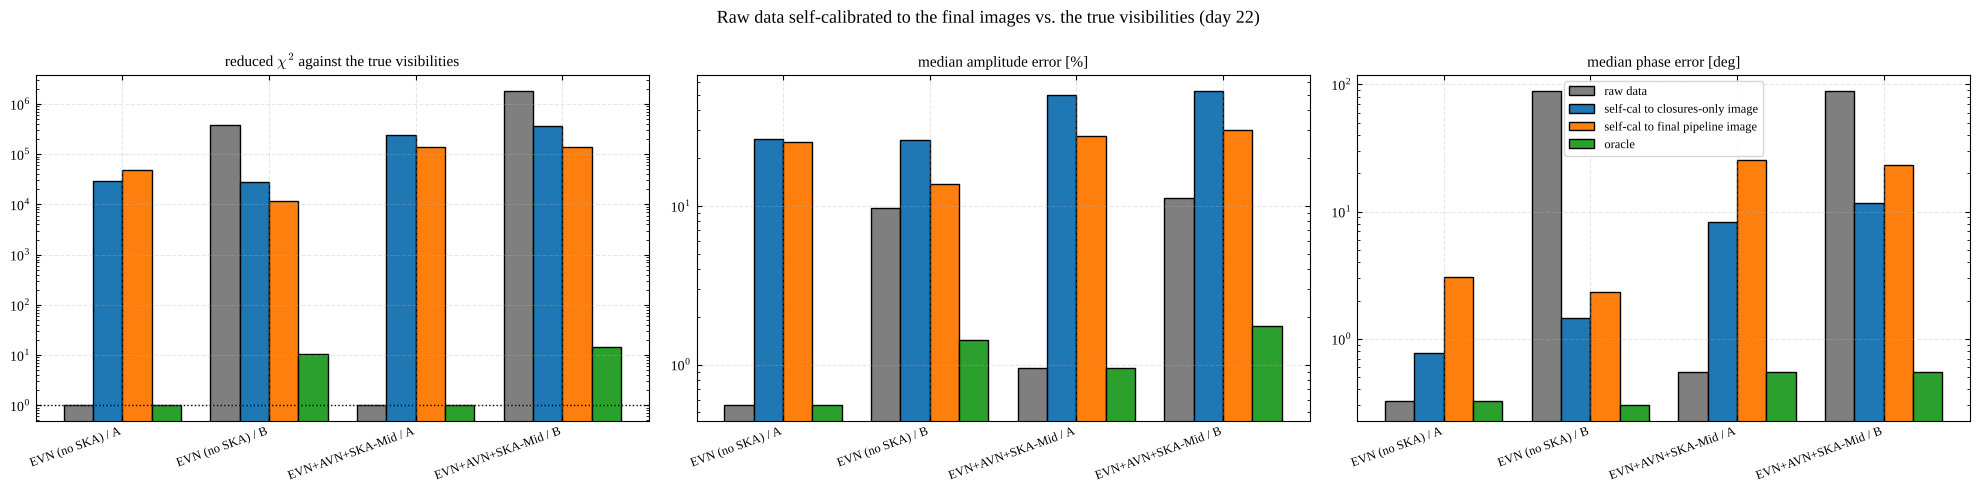

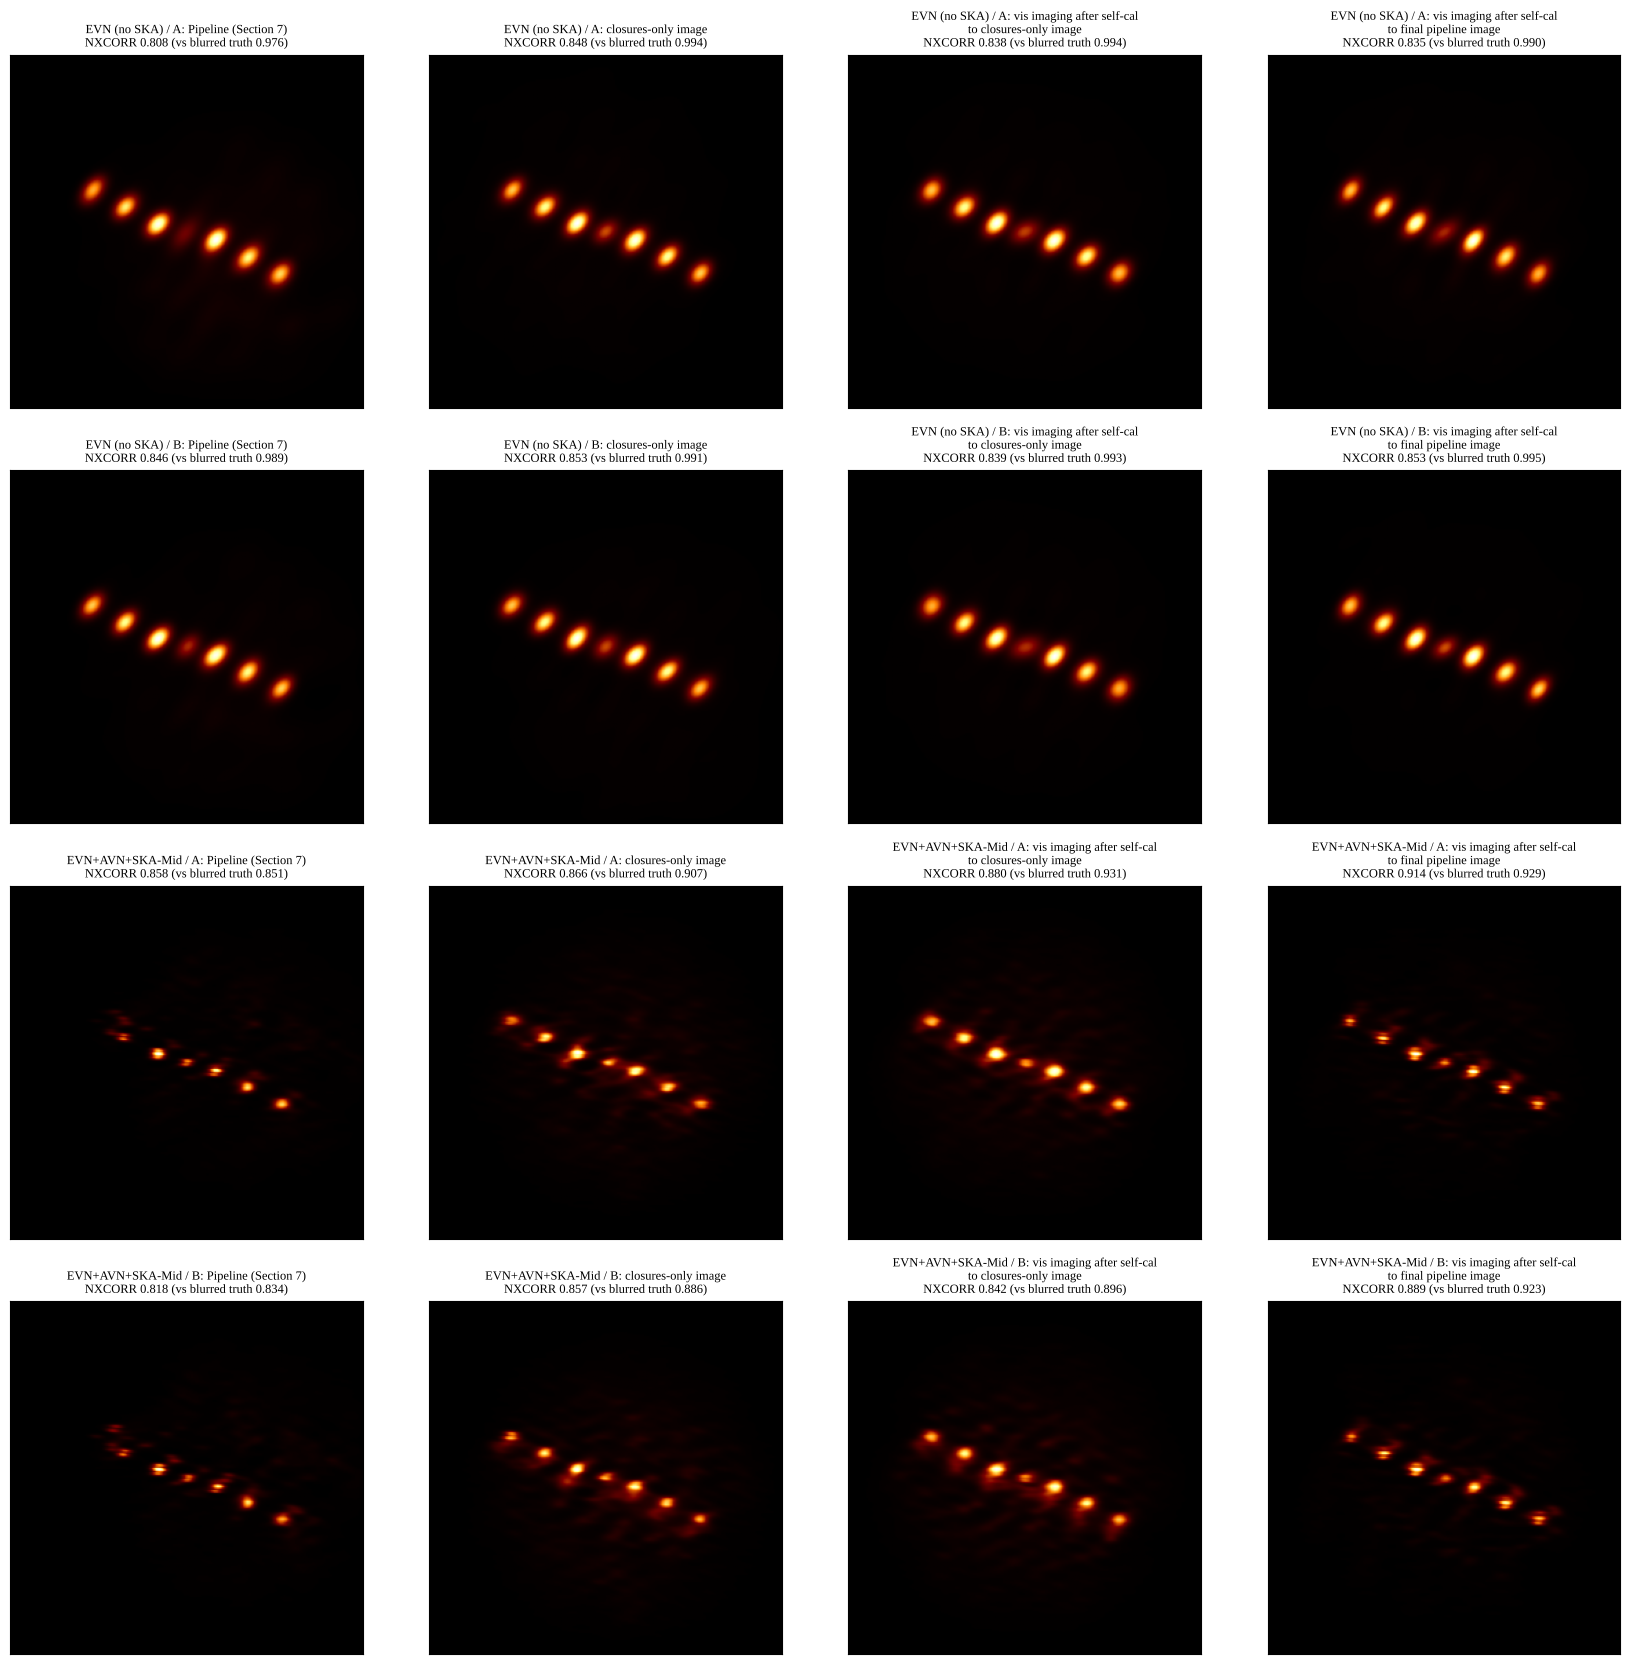

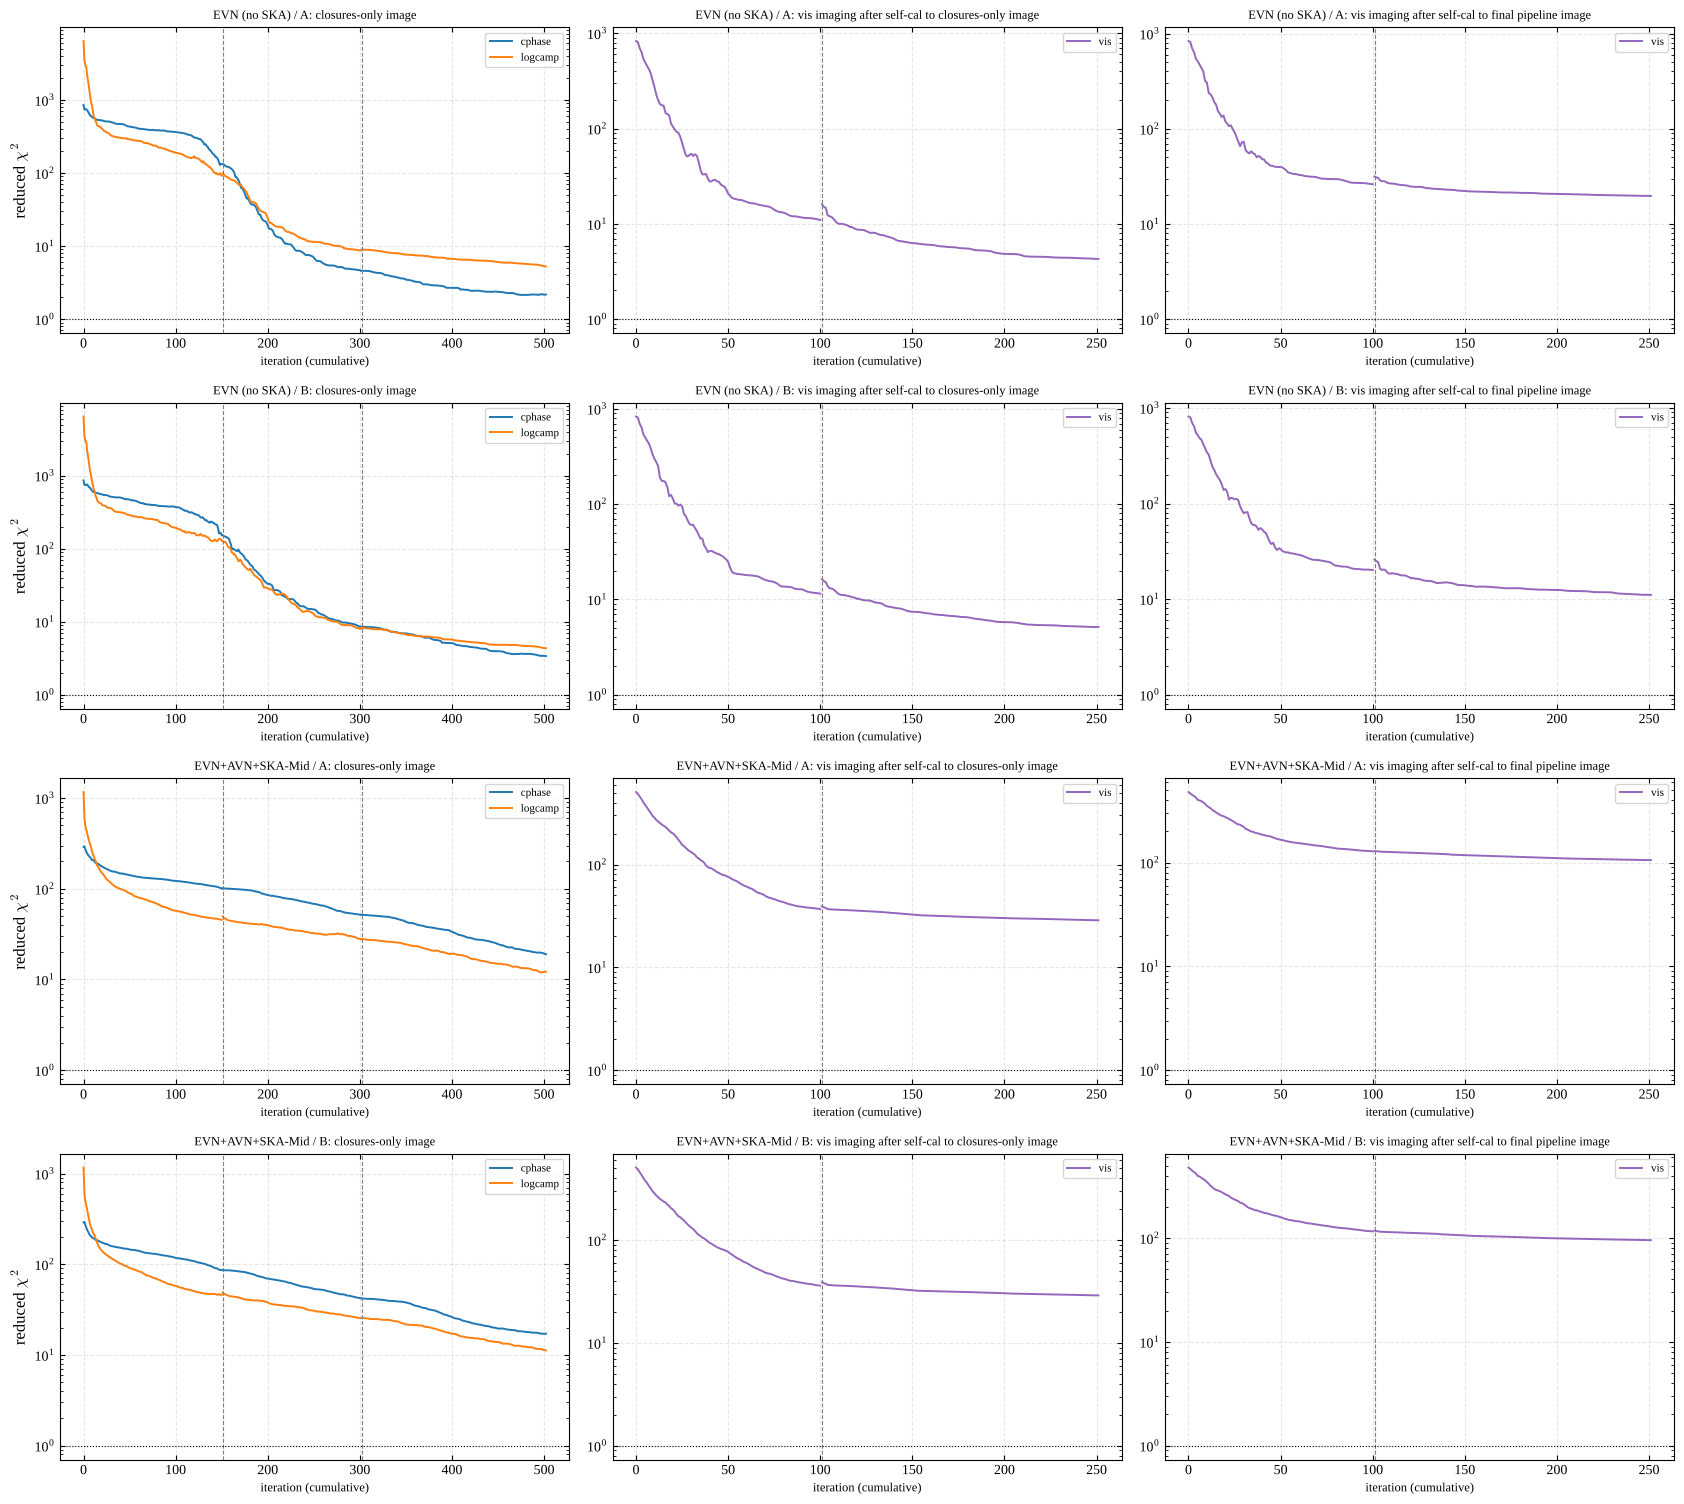

Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table
Section 8.4 done in 49.1 min.


In [27]:
RUN_SELFCAL_TEST = True
from scipy import ndimage

CLOSURE_ROUNDS = [   # same regularizers and iterations as IMAGING_ROUNDS, closure quantities only
    {'data_term': {'cphase': 50, 'logcamp': 50},
     'reg_term':  {'simple': 10, 'flux': 1e6, 'cm': 50},                  'maxit': 150},
    {'data_term': {'cphase': 80, 'logcamp': 80},
     'reg_term':  {'tv': 0.05, 'l1': 0.01, 'flux': 1e6, 'cm': 50},       'maxit': 150, 'blur_frac': 0.3},
    {'data_term': {'cphase': 100, 'logcamp': 100},
     'reg_term':  {'tv': 0.05, 'l1': 0.01, 'flux': 1e6, 'cm': 50},       'maxit': 200, 'blur_frac': 0.2},
]
VIS_ROUNDS = [       # imaging of the self-calibrated visibilities
    {'data_term': {'vis': 100},
     'reg_term':  {'simple': 10, 'flux': 1e4, 'cm': 50},                  'maxit': 100},
    {'data_term': {'vis': 100},
     'reg_term':  {'tv': 0.05, 'l1': 0.01, 'flux': 1e4, 'cm': 50},       'maxit': 150, 'blur_frac': 0.3},
]

def align_subpixel(im_model, im_truth):
    # Shift im_model (sub-pixel, Fourier shift) to the position that maximises its cross-correlation with im_truth.
    if im_truth.xdim != im_model.xdim:
        im_truth = im_truth.regrid_image(im_model.fovx(), im_model.xdim)
    a = im_model.imvec.reshape(im_model.ydim, im_model.xdim); b = im_truth.imvec.reshape(im_truth.ydim, im_truth.xdim)
    cc = np.real(np.fft.ifft2(np.fft.fft2(b) * np.conj(np.fft.fft2(a))))
    ny, nx = cc.shape; iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    parab = lambda m, c, p: 0.5 * (m - p) / (m - 2 * c + p) if (m - 2 * c + p) != 0 else 0.0
    dy = iy + parab(cc[(iy - 1) % ny, ix], cc[iy, ix], cc[(iy + 1) % ny, ix])
    dx = ix + parab(cc[iy, (ix - 1) % nx], cc[iy, ix], cc[iy, (ix + 1) % nx])
    dy = dy - ny if dy > ny / 2 else dy; dx = dx - nx if dx > nx / 2 else dx
    sh = np.clip(np.real(np.fft.ifft2(ndimage.fourier_shift(np.fft.fft2(a), (dy, dx)))), 0, None)
    out = im_model.copy(); out.imvec = (sh * im_model.total_flux() / sh.sum()).ravel()
    return out, np.hypot(dy, dx) * im_model.psize / RAD / 1e3

def vis_errors(o, ref, snr_min=5.0):
    # Visibilities of `o` vs. the noise-free visibilities of `ref` (same schedule).
    key = lambda d: list(zip(np.round(d['time'] * 3600).astype(int), d['t1'], d['t2']))
    r = dict(zip(key(ref.data), ref.data['vis']))
    kk = key(o.data); m = np.array([k in r for k in kk])
    v, s = o.data['vis'][m], o.data['sigma'][m]
    vt = np.array([r[k] for k, mm in zip(kk, m) if mm])
    hi = np.abs(vt) / s > snr_min
    return (float(np.mean(np.abs(v - vt) ** 2 / s ** 2) / 2),
            float(np.median(np.abs(np.abs(v[hi]) / np.abs(vt[hi]) - 1)) * 100),
            float(np.median(np.abs(np.degrees(np.angle(v[hi] * np.conj(vt[hi])))))))

def image_scores(raw, beam):
    aligned = TRUTH_IM.align_images([raw])[0][0]
    d_rec = aligned.blur_gauss(beam, RESTORE_BLUR).imarr()
    d_tb = TRUTH_IM.blur_gauss(beam, RESTORE_BLUR).imarr()
    return calc_nrmse(d_rec, TRUTH_IM.imarr()), calc_nxcorr(TRUTH_IM.imarr(), d_rec), calc_nxcorr(d_tb, d_rec), d_rec

SC = {}; SC_ROWS, SC_IMG_ROWS = [], []
if RUN_SELFCAL_TEST:
    t_sc = time.time()
    for key in RECON:
        a_key, s_key = key; obs = OBS[key][IMAGING_DAY]; beam = RECON[key]['beam']
        print(f"=== {a_key} / Scenario {s_key} ===")
        h_cl = []
        cl_raw, _, _, _ = run_imaging_pipeline(obs, ZBL, CLOSURE_ROUNDS, history=h_cl, verbose=False)
        SC[(key, 'closures-only image')] = dict(raw=cl_raw, hist=h_cl)
        SC_ROWS.append((f"{a_key} / {s_key}", 'raw data (no calibration)', np.nan) + vis_errors(obs, IDEAL[key]))
        for mname, model0 in (('closures-only image', cl_raw), ('final pipeline image', RECON[key]['raw'])):
            model, shift = align_subpixel(model0, TRUTH_IM)
            with no_plot(), quiet():
                cal = self_cal(obs, model, method='both', ttype=TTYPE)
            h_v = []
            v_raw, _, _, _ = run_imaging_pipeline(cal, ZBL, VIS_ROUNDS, history=h_v, verbose=False)
            SC[(key, f'self-cal to {mname}')] = dict(cal=cal, raw=v_raw, hist=h_v)
            SC_ROWS.append((f"{a_key} / {s_key}", f'self-cal to {mname}', shift) + vis_errors(cal, IDEAL[key]))
        if s_key == 'A':
            orc = obs; lab_o = 'oracle (A: data already calibrated)'
        else:
            with no_plot(), quiet():
                orc = self_cal(obs, TRUTH_IM, method='both', ttype=TTYPE)
            lab_o = 'oracle (true central frame)'
        SC_ROWS.append((f"{a_key} / {s_key}", lab_o, np.nan) + vis_errors(orc, IDEAL[key]))
        for what in ('closures-only image', 'self-cal to closures-only image', 'self-cal to final pipeline image'):
            nr, xc, xcb, _ = image_scores(SC[(key, what)]['raw'], beam)
            SC_IMG_ROWS.append({'Dataset': f"{a_key} / {s_key}", 'Image': what if what.startswith('closures') else f'vis imaging after {what}',
                                'NRMSE': nr, 'NXCORR': xc, 'NXCORR (vs blurred truth)': xcb,
                                'Flux ratio': SC[(key, what)]['raw'].total_flux() / ZBL})
        print(f"      done ({time.time() - t_sc:.0f} s)")

    df_sc = pd.DataFrame(SC_ROWS, columns=['Dataset', 'Visibilities', 'Model shift [mas]', 'chi2 vs true vis',
                                           'Median amp err [%]', 'Median phase err [deg]']).set_index(['Dataset', 'Visibilities'])
    display(df_sc.round(3))
    df_sc_img = pd.DataFrame(SC_IMG_ROWS).set_index(['Dataset', 'Image'])
    display(df_sc_img.round(3))

    # ---- Figure 15: visibility errors
    groups = ['raw data', 'self-cal to closures-only image', 'self-cal to final pipeline image', 'oracle']
    gcol = ['tab:gray', 'tab:blue', 'tab:orange', 'tab:green']
    dsets = [f"{k[0]} / {k[1]}" for k in RECON]
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for j, (col, ttl) in enumerate([(3, r'reduced $\chi^2$ against the true visibilities'), (4, 'median amplitude error [%]'),
                                    (5, 'median phase error [deg]')]):
        for g, (gname, c) in enumerate(zip(groups, gcol)):
            vals = [next(r[col] for r in SC_ROWS if r[0] == d and r[1].startswith(gname)) for d in dsets]
            ax[j].bar(np.arange(len(dsets)) + (g - 1.5) * 0.2, vals, 0.2, color=c, edgecolor='k', label=gname)
        ax[j].set_xticks(range(len(dsets))); ax[j].set_xticklabels(dsets, rotation=20, ha='right', fontsize=9)
        ax[j].set_yscale('log'); ax[j].set_title(ttl, fontsize=11)
    ax[0].axhline(1, color='k', ls=':', lw=1); ax[2].legend(fontsize=9)
    fig.suptitle(f'Raw data self-calibrated to the final images vs. the true visibilities (day {IMAGING_DAY})', fontsize=13)
    plt.tight_layout(); save_fig(fig, "15_selfcal_to_final_images_visibility_errors"); plt.show()

    # ---- Figure 16: images
    cols = [('Pipeline (Section 7)', None), ('closures-only image', 'closures-only image'),
            ('vis imaging after self-cal\nto closures-only image', 'self-cal to closures-only image'),
            ('vis imaging after self-cal\nto final pipeline image', 'self-cal to final pipeline image')]
    fig, axes = plt.subplots(len(RECON), 4, figsize=(17, 4.2 * len(RECON)))
    lim = LIMIT_MAS if 'LIMIT_MAS' in globals() else OBSERVATION_FOV / 2000.0
    for r_, key in enumerate(RECON):
        for c_, (ttl, what) in enumerate(cols):
            raw = RECON[key]['raw'] if what is None else SC[(key, what)]['raw']
            nr, xc, xcb, d = image_scores(raw, RECON[key]['beam'])
            axes[r_, c_].imshow(d * 1e3, cmap='afmhot', origin='upper', extent=[lim, -lim, -lim, lim])
            axes[r_, c_].set_title(f"{key[0]} / {key[1]}: {ttl}\nNXCORR {xc:.3f} (vs blurred truth {xcb:.3f})", fontsize=9)
            axes[r_, c_].set_xticks([]); axes[r_, c_].set_yticks([])
    plt.tight_layout(); save_fig(fig, "16_images_closures_only_and_selfcalibrated_visibilities"); plt.show()

    # ---- Figure 17: chi^2 at every iteration
    TERMS2 = {'cphase': 'tab:blue', 'logcamp': 'tab:orange', 'amp': 'tab:red', 'vis': 'tab:purple'}
    panels = [(f"{k[0]} / {k[1]}: {w}", SC[(k, w)]['hist']) for k in RECON
              for w in ('closures-only image', 'self-cal to closures-only image', 'self-cal to final pipeline image')]
    fig, axes = plt.subplots(len(RECON), 3, figsize=(17, 3.8 * len(RECON)), squeeze=False)
    for ax, (ttl, h) in zip(axes.ravel(), panels):
        off, edges, seen = 0, [], set()
        for r in sorted({x['round'] for x in h}):
            rec = [x for x in h if x['round'] == r]; xs = np.array([off + x['iter'] for x in rec])
            for t, c in TERMS2.items():
                if t in rec[0]:
                    ax.semilogy(xs, [x[t] for x in rec], color=c, lw=1.4, label=None if t in seen else t); seen.add(t)
            off = xs.max() + 1; edges.append(off)
        for e in edges[:-1]: ax.axvline(e, color='gray', ls='--', lw=0.8)
        ax.axhline(1, color='k', ls=':', lw=0.8)
        ax.set_title(ttl.replace('self-cal to', 'vis imaging after self-cal to'), fontsize=9)
        ax.set_xlabel('iteration (cumulative)', fontsize=9); ax.legend(fontsize=8)
    for ax in axes[:, 0]: ax.set_ylabel(r'reduced $\chi^2$')
    plt.tight_layout(); save_fig(fig, "17_chi2_convergence_closures_only_and_selfcalibrated_visibilities"); plt.show()

    # ---- Save: calibrated UVFITS and tables (also included in the export of Section 10)
    os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)
    for (key, what), d in SC.items():
        if 'cal' in d:
            tag = ARRAY_TAG[key[0]] + '_' + key[1]
            os.makedirs(f"{UV_DIR}/{tag}", exist_ok=True)
            fn = 'selfcal_to_closures_image' if 'closures' in what else 'selfcal_to_final_pipeline_image'
            d['cal'].save_uvfits(f"{UV_DIR}/{tag}/obs_day_{IMAGING_DAY:02d}_{fn}.uvfits")
    df_sc.to_csv(f"{OUT_DIR}/tables/selfcal_to_final_images_visibility_errors_day{IMAGING_DAY:02d}.csv")
    df_sc_img.to_csv(f"{OUT_DIR}/tables/selfcal_to_final_images_reconstructions_day{IMAGING_DAY:02d}.csv")
    print(f"Section 8.4 done in {(time.time() - t_sc) / 60:.1f} min.")

## 9. Discussion of the results

The numbers quoted here are those of the run saved in this notebook. The two arrays are the **EVN (no SKA)** (10 stations) and the **EVN + AVN + SKA-Mid** (19 stations: the same 10 EVN stations, 4 SKA-Mid elements including the phased SKA-Mid core `S5`, and 5 AVN stations). The source model, the schedule and the thermal noise of Scenario A are reproducible. The gains and phases of Scenario B, however, depend on the Python hash seed, and RML imaging is a non-convex optimisation, so the single-frame NXCORR changes by up to ~0.1 between runs. Only larger differences are discussed.

**Arrays and uv-coverage (Section 5).** On the imaging day the EVN (no SKA) gives 3,999 visibilities on 45 baselines, and the EVN + AVN + SKA-Mid 15,089 on 171; every nominal baseline is active. The African stations (AVN and SKA-Mid) stretch the coverage from 43 to 147 Mλ, mostly north–south, and the fitted beam goes from 7.6 × 4.3 mas (PA 136°) to 3.9 × 0.9 mas (PA 86°). SKA-Mid also adds very short baselines between its own elements (down to 0.01 Mλ), which measure essentially the total flux. Two caveats come with the gain in resolution:

* The EVN–Africa baselines, which carry it, are the faintest data of the array, because the source is resolved on them. Their median SNR is ~8, against ~90 for EVN–EVN and ~150 for Africa–Africa (the latter dominated by the phased SKA-Mid core).
* The EVN + AVN + SKA-Mid dirty beam has strong north–south side-lobes close to the main lobe, the signature of the gap between the short intra-continental and the long intercontinental spacings.

**Corruption and closure phases (Section 5.6).** Scenario A shows only thermal noise: amplitude scatter of 0.9% (EVN) and 2.8% (EVN + AVN + SKA-Mid), visibility-phase scatter of 9° and 22°. Scenario B changes the amplitudes by 15–18% and makes the visibility phases essentially uniform (circular scatter 169–189°). The closure phases of A and B, however, are statistically identical (robust scatter 1.2° vs. 1.2° for the EVN, 4.9° vs. 4.7° for the EVN + AVN + SKA-Mid): the antenna-based errors cancel in every triangle.

**The campaign in the data domain (Section 6).** The total flux of the source varies between 1.8 and 5.6 Jy (mean 4.1 ± 0.8 Jy) as blobs are ejected, move out and fade. The median SNR per day is 134 ± 56 (EVN) and 39 ± 15 (EVN + AVN + SKA-Mid, lower because of the faint long baselines). The shortest 10% of the baselines see 58 ± 15% (EVN) and 65 ± 9% (EVN + AVN + SKA-Mid) of the total flux: the short SKA-Mid baselines recover more of the extended emission, with less day-to-day variation.

**Imaging of day 22 (Sections 7–8).**

| | NXCORR | NXCORR vs. truth at the same resolution | dynamic range | flux ratio | final χ² (cphase / amp) |
|---|---|---|---|---|---|
| EVN (no SKA) / A | 0.81 | 0.98 | ~110 | 1.11 | 50 / 125 |
| EVN (no SKA) / B | 0.85 | 0.99 | ~170 | 1.14 | 20 / 73 |
| EVN + AVN + SKA-Mid / A | 0.86 | 0.85 | ~140 | 1.03 | 77 / 173 |
| EVN + AVN + SKA-Mid / B | 0.82 | 0.83 | ~110 | 1.04 | 61 / 139 |

* **Scenario B is recovered as well as Scenario A** with both arrays; the differences (≤ 0.04 in NXCORR) are within the run-to-run scatter.
* **The EVN (no SKA) images are very faithful at their own, coarse resolution** (NXCORR 0.98–0.99 against the truth convolved with the EVN beam).
* **The EVN + AVN + SKA-Mid images resolve the components better but less faithfully** (0.83–0.85 at their own, much finer resolution): residual north–south side-lobe structure and some flux redistributed between neighbouring components. That is the price of resolution obtained from the low-SNR EVN–Africa baselines and of the side-lobes of the beam.
* **Convergence (figure 14).** All 12 rounds converged without retries. The χ² of the closure phases and amplitudes is still decreasing at the end of round 3 and stays at ~20–190, not 1: part of the mismatch is irreducible (no single static image reproduces a source that changes during the track), the rest is the regularization and the finite number of iterations.

**Self-calibration to the final images (Section 8.4): how well do the closures work?**

| | Phase error (EVN / EVN+AVN+SKA-Mid) | Amplitude error | χ² vs. true visibilities |
|---|---|---|---|
| raw data, B | 89° / 89° | 10% / 11% | 4 × 10⁵ / 2 × 10⁶ |
| self-cal to the **closures-only** image (A, B) | **0.8–1.4°** / **8–12°** | 26% / 50–53% | 3 × 10⁴ / 2–4 × 10⁵ |
| self-cal to the final **pipeline** image (A, B) | 2.3–3.1° / 23–26° | 14–25% / 28–30% | 1–5 × 10⁴ / 1.4 × 10⁵ |
| oracle (true central frame), B | 0.3° / 0.5° | 1.4% / 1.8% | 11 / 14 |

* **The closures alone give the best phase model with both arrays.** Self-calibration to the closures-only image (cphase + logcamp, no calibration) brings the phase errors from 89° to ~1° with the EVN (no SKA) and to 8–12° with the EVN + AVN + SKA-Mid. The final pipeline image, which also fitted amplitudes and complex visibilities, does worse on the phases (2–3° and 23–26°).
* **Neither image is a good amplitude model** at this level: amplitude errors of 14–53%, much larger than the gain errors of the raw data. The images (NRMSE 0.6–0.7 against the unblurred truth) do not reproduce the flux distribution on the long baselines, and an amplitude self-calibration copies their errors into the data. The oracle shows that the variability of the source within the track is not the limit here (1.4–1.8% with the true central frame).
* **One more self-calibration step helps the EVN + AVN + SKA-Mid.** Imaging the visibilities self-calibrated to the pipeline image raises the NXCORR from 0.86 to 0.91 (A) and from 0.82 to 0.89 (B), and from 0.85 to 0.93 and from 0.83 to 0.92 against the truth at the same resolution. With the EVN (no SKA) the change is small (0.81 → 0.84 in A, 0.85 → 0.85 in B; 0.99 at its own resolution), because its images are already about as good as its resolution allows.
* **Practical conclusion:** use the closures to fix the phases (phase-only self-calibration to a closure image), and iterate imaging and self-calibration more than once for the EVN + AVN + SKA-Mid before trusting amplitude calibration.

**What the single frame does not tell.** The metrics of one frame mix the array and scenario effects with a single noise realisation. The 43-day statistics of the full-campaign script (mean ± standard deviation of every metric per array, scenario and variability rate), including the 5× and 20× variability rates where the static-image assumption breaks down, are the quantitative answer to the question of the project.

## 10. Export everything

Collects in `binary_jet_results/` and in one zip file (`binary_jet_results.zip`):
* `uvfits/`: the observations of the imaging day (or of every day, with `SAVE_UVFITS = 'all'`) for the four datasets, as `.uvfits` (AIPS, CASA, Difmap) and `.txt`, plus the noise-free reference of the imaging day (`IDEAL_*`);
* `images/`: the ground truth of the imaging day and the four reconstructions (unrestored and restored) as FITS;
* `figures/`: every figure of the notebook as PNG;
* `tables/`: campaign summary, corruption statistics, imaging metrics, final $\chi^2$ per round, and the configuration (`config.json`), plus a `README.txt`.

In Google Colab the zip file is downloaded automatically.

In [28]:
import shutil, datetime
TAB_DIR = f"{OUT_DIR}/tables"
os.makedirs(TAB_DIR, exist_ok=True)

# ---- images (FITS)
TRUTH_IM.save_fits(f"{IMG_DIR}/truth_day{IMAGING_DAY:02d}.fits")
for (a_key, s_key), R in RECON.items():
    tag = f"{ARRAY_TAG[a_key]}_{s_key}"
    R['raw'].save_fits(f"{IMG_DIR}/recon_unrestored_{tag}_day{IMAGING_DAY:02d}.fits")
    R['restored'].save_fits(f"{IMG_DIR}/recon_restored_{tag}_day{IMAGING_DAY:02d}.fits")

# ---- visibilities of the imaging day (always), including the noise-free reference
with quiet():
    for (a_key, s_key) in OBS:
        tag = f"{ARRAY_TAG[a_key]}_{s_key}"
        os.makedirs(f"{UV_DIR}/{tag}", exist_ok=True)
        p = f"{UV_DIR}/{tag}/obs_day_{IMAGING_DAY:02d}"
        if not os.path.exists(p + ".uvfits"):
            OBS[(a_key, s_key)][IMAGING_DAY].save_uvfits(p + ".uvfits"); OBS[(a_key, s_key)][IMAGING_DAY].save_txt(p + ".txt")
        IDEAL[(a_key, s_key)].save_uvfits(f"{UV_DIR}/{tag}/IDEAL_noisefree_day_{IMAGING_DAY:02d}.uvfits")

# ---- tables
df_campaign.to_csv(f"{TAB_DIR}/campaign_summary.csv")
df_corr.to_csv(f"{TAB_DIR}/corruption_statistics_day{IMAGING_DAY:02d}.csv")
df_metrics.to_csv(f"{TAB_DIR}/imaging_metrics_day{IMAGING_DAY:02d}.csv")
df_chi2.to_csv(f"{TAB_DIR}/chi2_final_per_round_day{IMAGING_DAY:02d}.csv")
df_arrays.to_csv(f"{TAB_DIR}/array_summary_day{IMAGING_DAY:02d}.csv")
for f in ("campaign_summary.csv", f"imaging_metrics_day{IMAGING_DAY:02d}.csv"):   # older copies in the top folder
    if os.path.exists(f"{OUT_DIR}/{f}"): os.remove(f"{OUT_DIR}/{f}")
cfg = {k: (v if isinstance(v, (int, float, str, bool, list, dict)) else str(v))
       for k, v in globals().items()
       if k in ("N_DAYS", "IMAGING_DAY", "FRAMES_PER_DAY", "TIME_FACTOR", "SEED", "RF_HZ", "BW_HZ", "TINT_S", "TADV_S",
                "ELEVMIN", "WINDOW_HOURS", "MJD_START", "OBSERVATION_FOV", "NPIX", "TTYPE", "SCENARIOS", "IMAGING_ROUNDS",
                "PRIOR_FWHM_FRAC", "RESTORE_BLUR")}
with open(f"{TAB_DIR}/config.json", "w") as f:
    json.dump(cfg, f, indent=2, default=str)
shutil.copy("data/EVN_noSKA_array.txt", f"{TAB_DIR}/array_EVN_noSKA.txt"); shutil.copy("data/EVN_AVN_SKAMid_array.txt", f"{TAB_DIR}/array_EVN_AVN_SKAMid.txt")
with open(f"{OUT_DIR}/README.txt", "w") as f:
    f.write(f"""Binary (SS 433-like) jet, 5 GHz, EVN (no SKA) vs EVN+AVN+SKA-Mid, RADIOBLOCKS scenarios A and B (single-frame delivery notebook)
Generated: {datetime.datetime.now():%Y-%m-%d %H:%M}
Campaign: {N_DAYS} days, imaging day {IMAGING_DAY}, window {START_HR:.2f}-{END_HR:.2f} h UTC, tint={TINT_S}s tadv={TADV_S}s, bw={BW_HZ/1e6:.0f} MHz, ttype={TTYPE}
uvfits/  : observations (.uvfits, .txt) per array_scenario, plus IDEAL_noisefree (imaging day)
images/  : ground truth and reconstructions (FITS) of the imaging day
figures/ : all figures (PNG)
tables/  : campaign summary, corruption statistics, imaging metrics, chi2 per round, array summary, config.json, array files
""")

zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
n_files = sum(len(fs) for _, _, fs in os.walk(OUT_DIR))
print(f"{n_files} files written under '{OUT_DIR}/' and zipped as '{zip_path}':")
for sub_ in sorted(os.listdir(OUT_DIR)):
    p = f"{OUT_DIR}/{sub_}"
    print(f"  {sub_}{'/' if os.path.isdir(p) else ''}" + (f"  ({sum(len(fs) for _, _, fs in os.walk(p))} files)" if os.path.isdir(p) else ""))
try:                                    # automatic download in Google Colab
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

57 files written under 'binary_jet_results/' and zipped as '/home/claude/work2/v2_bin/binary_jet_results.zip':
  README.txt
  figures/  (17 files)
  images/  (9 files)
  tables/  (10 files)
  uvfits/  (20 files)


## 11. Conclusions and limitations

* **What the study measures.** How well a 43-day campaign of a time-variable, precessing, double-sided jet can be followed at 5 GHz with the **EVN (no SKA)** and with the **EVN + AVN + SKA-Mid**, under thermal noise only (Scenario A) and with uncalibrated station gains and phases (Scenario B). This notebook does the full campaign in the data domain and images one frame; the script `binary_jet_VLBI_campaign_full.py` images every day, for both scenarios and three rates of source evolution within a track.
* **Arrays.** Adding the AVN and SKA-Mid quadruples the data (15,089 vs. 3,999 visibilities per day), halves the major axis of the beam (3.9 vs. 7.6 mas) and shrinks the minor axis five-fold (0.9 vs. 4.3 mas). However:
  - the long EVN–Africa baselines have a median SNR of only ~8 (against ~90 for EVN–EVN and ~150 for Africa–Africa, i.e. AVN + SKA-Mid), so the extra resolution comes from the weakest data of the array;
  - the dirty beam has strong north–south side-lobes near the main lobe.

  For the imaged frame, the EVN + AVN + SKA-Mid images resolve the components better, but are less faithful at their own resolution than the EVN (no SKA) images are at theirs. One more self-calibration and imaging step improves them markedly (NXCORR 0.82–0.86 → 0.89–0.91, Section 8.4).
* **Scenarios.** In the data domain, the gain and phase errors of Scenario B scramble the visibility phases completely (circular scatter ~170°) and change the amplitudes by ~15%, while the closure phases of A and B are statistically identical: the antenna-based errors cancel. In the image domain, the closure-phase + amplitude pipeline with self-calibration recovers Scenario B to the same level as Scenario A.
* **How well do the closures work? (Section 8.4).** Self-calibrating the raw data to the closures-only image fixes the phases better than to any other image (~1° with the EVN (no SKA), 8–12° with the EVN + AVN + SKA-Mid, from 89°), but neither the closures-only nor the pipeline images are good amplitude models at this level (14–53% amplitude errors), while the true central frame gives 1.4–1.8%. Phase-only self-calibration to a closure image, followed by more than one imaging/self-calibration iteration, is the recommended path for the EVN + AVN + SKA-Mid.
* **Why there is no Scenario C here.** The structured atmospheric corruptions (ionospheric dTEC and tropospheric delay screens) with in-band and in-scan decorrelation used in the static notebooks would have to be continuous over 43 days and averaged over channels and sub-integrations for ~15,000 visibilities per day and array, multiplying a run time that is already ~2–4 days per scenario. It would also mix two effects (source variability and structured phase errors) that this study is designed to separate. The static 5 GHz notebooks show that at C-band the dispersive (ionospheric) part is negligible and the decorrelation comes from their tropospheric (delay) part, which a standard fringe fit removes.
* **Imaging choices that the dynamic case required** (shared by the notebook and the script):
  - a 2% systematic error budget on the data used for imaging, because the phased SKA-Mid baselines reach SNR ~8,600 and a source that evolves during the track cannot be fitted by one static image at that level;
  - a small random perturbation of the Gaussian prior, because a point-symmetric start image on point-symmetric data makes the optimiser stall;
  - a stall guard on round 1 and 150 / 150 / 200 iterations per round (with 50 / 50 / 80 the rounds stop far from convergence).
* **Reproducibility and statistics.** The gains and phases of Scenario B are drawn by `ehtim` with seeds derived from Python's string hash, which changes between sessions, and RML imaging is a non-convex optimisation. Single-frame metrics therefore change by up to ~0.1 in NXCORR between runs. The 43-day statistics of the script (mean ± standard deviation per array, scenario and variability rate) are the robust result; a single frame is an illustration.
* **Limitations of the model and of the set-up.**
  - The sky model is a toy SS 433-like jet: Gaussian blobs on a helix, symmetric jet and counter-jet, no Doppler boosting, no spectral index.
  - The observing window is fixed (the uv-coverage is the same every day, by design), and a single elevation limit is applied to all stations.
  - The SEFDs of the AVN stations and of the SKA-Mid elements (including the phased SKA-Mid core, 3.1 Jy) are assumptions.
  - The total flux is assumed known (strong flux regulariser), as in the other notebooks of the project.
  - Imaging assumes a static source within a track, which is the main limitation for the 5× and 20× variability rates of the script.
* **Natural extensions.**
  - Image every day here too (that is the script), and add the self-calibration test of Section 8.4 to it.
  - Use the real day-to-day sidereal shift of the window.
  - Image with a dynamic (movie) regulariser instead of frame by frame.
  - Add Scenario C for a few selected days only.
  - Average the single-frame metrics over several noise realisations.

## References

* Chael, A. A., et al. 2018, *Interferometric imaging directly with closure phases and closure amplitudes*, ApJ 857, 23 (`ehtim`, https://github.com/achael/eht-imaging).
* Chael, A. A., et al. 2016, *High-resolution linear polarimetric imaging for the Event Horizon Telescope*, ApJ 829, 11 (RML imaging with `ehtim`).
* EVN status table (SEFDs of the EVN stations): https://evlbi.org/sites/default/files/shared/EVNstatus.txt
* Li, Y., Xu, Y., Li, J., et al. 2024, *VLBI with SKA: Possible Arrays and Astrometric Science*, RAA, arXiv:2404.14663 (positions and SEFDs of the EVN, AVN and SKA-Mid antennas).
* RADIOBLOCKS project: scenario definitions A, B, C shared with the static notebooks of this delivery; full-campaign script `binary_jet_VLBI_campaign_full.py`.